In [310]:
from typing import List
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt

import cvxpy as cp
import gurobipy as gp

from Components.RecedingHorizon import RecedingHorizon
from Components.System import SimpleSquareExample
from Components.Model import SquareCoarseModel, SquareCoarseExtendedModel
from Components.Controllers import LTI_LQRc_RHG, LTI_LQRc_RHG_mixed_state
from Components.Solver import fbrs

In [ ]:
# Reload scripts when executed
%load_ext autoreload
%autoreload 2

np.set_printoptions(linewidth=np.inf)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [312]:
parameter_file = "Components/Setup/aquifer_parameters.json"

In [313]:
# Initialize Model
model = SquareCoarseModel(parameter_file, boundary_condition="Constant Head")

# Find steady-state equilibrium (v-GNE)

$x_s = Ax_s + Bu_s + C$ and  $J^v(x_s,u_s^v) = x_s^T \Gamma^v u_s^v + \Xi^v u_s^v$

So with $\tilde X_s^1 = [x_s^T \ {u_s^1}^T]^T$ and $\tilde X_s^v = u_s^v \ \forall v\ge 2$ , it yields that:

$J^1(\tilde X_s^1, \tilde X_s^v) = {\tilde X_s^1}^T \begin{bmatrix} 0 & \Gamma^1 \\ 0 & 0 \end{bmatrix} \tilde X_s^1 + [0 \ \Xi^1] \tilde X_s^1$,

$J^v(\tilde X_s^1, \tilde X_s^v) = {\tilde X_s^1}^T \begin{bmatrix} \Gamma^v \\ 0 \end{bmatrix} \tilde X_s^v + \Xi^v \tilde X_s^v \forall v\ge 2$

and $\begin{bmatrix} I-A & -B \end{bmatrix} col(\tilde X_s^v)_{v\ge 1} = C$

So:

$\nabla_{\tilde X_s^1} J^v(\tilde X_s^1, \tilde X_s^v) = \begin{bmatrix} 0 & \Gamma^1 \\ {\Gamma^1}^T & 0 \end{bmatrix}\tilde X_s^1 + [0 \ \Xi^1]^T$

$\nabla_{\tilde X_s^v} J^v(\tilde X_s^1, \tilde X_s^v) = ( {\tilde X_s^1}^T \begin{bmatrix} \Gamma^v \\ 0 \end{bmatrix} + \Xi^v)^T = \begin{bmatrix} {\Gamma^v}^T & 0 \end{bmatrix} \tilde X_s^1 + {\Xi^v}^T $

and
$\begin{bmatrix}I-A & -B \\ A-I & B \\ H_x & 0 \\ 0 & H_u \end{bmatrix} col(\tilde X_s^v)_{v\ge 1} \le \begin{bmatrix} C \\ C \\ h_x \\ h_u \end{bmatrix}$
<!-- $\nabla_{u_v} J^v(\tilde X_s) = (x^T \Gamma + \Xi^v)^T = [\Gamma^T \ 0 ]\tilde X_s^T + {\Xi^v}^T$ -->

In [314]:
nx = model.n_col*model.n_row
nu = sum(model.nu_v)
# Construct cost matrices
F = np.zeros((nx+nu, nx+nu))
F[:nx, nx:nx+model.nu_v[0]] = model.Gamma_v[0].toarray()
F[nx:nx+model.nu_v[0], :nx] = model.Gamma_v[0].toarray().T
F[nx+model.nu_v[0]:, :nx] = \
    np.vstack([Gamma.toarray().T for Gamma in model.Gamma_v[1:]])
f = np.vstack([np.hstack([np.zeros((1,nx)), model.Xi_v[0]]).T] + [Xi.T for Xi in model.Xi_v[1:]])

In [315]:
# Construct constraint matrices
H_stability = np.hstack([np.eye(nx)-model.A,
                         np.hstack([-B.toarray() for B in model.B_v])])
H = np.vstack([
    H_stability,
    -H_stability,
    sp.block_diag([model.H_x, sp.block_diag(model.H_u_v)]).toarray()
])
h = np.vstack([
    model.C,
    model.C,
    model.h_x.toarray(),
    np.vstack([h_u.toarray() for h_u in model.h_u_v])
])

In [316]:
# Find equilibrium
X_s_0 = np.zeros((nx+nu, 1))
dual_0 = np.zeros((H.shape[0], 1))
#X_s, dual, E, out = fbrs(F, f, H, h, X_s_0, dual_0)

In [317]:
np.linalg.det(F)

np.float64(0.0)

Alternative:

$x_s = (I-A)^{-1} (Bu_s + C)$ and

$J^v(x_s,u_s^v) = x_s^T \Gamma^v u_s^v + \Xi^v u_s^v = u_s^T \left(((I-A)^{-1} B)^T \Gamma^v \right) u_s^v + \left(((I-A)^{-1}C)^T \Gamma^v + \Xi^v\right) u_s^v
:= u_s^T \tilde \Gamma^v u_s^v + \tilde \Xi^v u_s^v$

So:

$J^v(u_s^v, u_s^{-v}) = {u_s^v}^T \tilde \Gamma^v_{[v,:]} u_s^v + {u_s^{-v}}^T \tilde \Gamma^v_{[-v,:]} u_s^v + \tilde \Xi^v u_s^v$

So:

$\nabla_{u_s^v} J^v(\tilde u_s^v, \tilde u_s^{-v}) = (\tilde \Gamma^v_{[v,:]} + {\tilde \Gamma^v_{[v,:]}}^T) u_s^v + {\tilde \Gamma^v_{[:,-v]}}^T u_s^{-v} + {\tilde \Xi^v}^T$

and
$\begin{bmatrix}H_u \\ H_x (I-A)^{-1} B \end{bmatrix} col(u_s^v) \le \begin{bmatrix} h_u \\ h_x - (I-A)^{-1} C \end{bmatrix}$

In [318]:
# Construct new Gamma and Xi matrices
I_A_inv = np.linalg.inv(np.eye(nx)-model.A)
B = np.hstack([B.toarray() for B in model.B_v])
Gamma_v_tilde = [(I_A_inv@B).T @ Gamma for Gamma in model.Gamma_v]
Xi_v_tilde = [(I_A_inv@model.C).T @ model.Gamma_v[v] + Xi  for v, Xi in enumerate(model.Xi_v)]

In [319]:
# Construct cost matrices
F = sp.block_diag([Gamma_v_tilde[v][sum(model.nu_v[:v]): sum(model.nu_v[:v+1])].T \
                   for v in range(model.n_agent)]).toarray()
F += np.vstack([Gamma.T for Gamma in Gamma_v_tilde])
f = np.vstack([Xi.T for Xi in Xi_v_tilde])

In [320]:
# Construct constraint matrices
H = np.vstack([
    sp.block_diag(model.H_u_v).toarray(),
    model.H_x @ I_A_inv @ B
])
h = np.vstack([
    sp.vstack(model.h_u_v).toarray(),
    model.h_x.toarray() - I_A_inv @ model.C
])

In [321]:
# Find equilibrium
u_s_0 = 1000*np.ones((nu, 1))
dual_0 = np.zeros((H.shape[0], 1))
u_s, dual, E, out = fbrs(F, f, H, h, u_s_0, dual_0)
x_s = I_A_inv @ (B @ u_s + model.C)

In [322]:
u_s, x_s.T

(array([[ -845.1870679 ],
        [ -584.66665444],
        [ -817.65051264],
        [-1000.        ]]),
 array([[9.88826301, 9.76250964, 9.62960197, 9.56645286, 9.77320876, 9.79054241, 9.53217357, 9.1894454 , 8.86300069, 9.52638219, 9.74173305, 9.38619682, 8.73300538, 8.77295862, 9.46931931, 9.79019297, 9.53787529, 9.2406502 , 9.17291431, 9.57793643, 9.88116353, 9.73446117, 9.51880584, 9.10011198, 9.6695121 ]]))

In [323]:
u_test = np.array([[-1000, 0, 0, 0]]).T
x_test = I_A_inv @ (B @ u_test + model.C)
x_test.T

array([[9.94343891, 9.88687783, 9.84917044, 9.88687783, 9.94343891, 9.88687783, 9.75490196, 9.62292609, 9.75490196, 9.88687783, 9.84917044, 9.62292609, 9.13273002, 9.62292609, 9.84917044, 9.88687783, 9.75490196, 9.62292609, 9.75490196, 9.88687783, 9.94343891, 9.88687783, 9.84917044, 9.88687783, 9.94343891]])

In [324]:
1*(10-9.99) - 2*1

-1.9900000000000002

In [325]:
(sp.block_diag([u_test.T @ Gamma for Gamma in Gamma_v_tilde]) + sp.block_diag(Xi_v_tilde)) @ u_test

array([[-1132.73001508],
       [    0.        ],
       [    0.        ]])

In [326]:
x_test.T @ model.Gamma_v[0] @ u_test[0] + model.Xi_v[0] @ u_test[0]

array([-1132.73001508])

In [327]:
(H @ u_test <= h).T

array([[ True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True,  True]])

In [328]:
u_opt_relax = -np.linalg.inv(F) @ f
u_opt_relax

array([[ -829.05010313],
       [ -562.60678703],
       [ -816.21988081],
       [-1324.06605347]])

In [329]:
x_opt_relax = I_A_inv @ (B @ u_opt_relax + model.C)
x_opt_relax.T

array([[9.88648635, 9.75930998, 9.6257195 , 9.56259029, 9.77049447, 9.78663543, 9.52503405, 9.18097775, 8.85414718, 9.51938758, 9.73502133, 9.37321303, 8.71901027, 8.75406423, 9.45290869, 9.78023685, 9.51378647, 9.19337451, 9.09334136, 9.53818293, 9.87213959, 9.7083215 , 9.44735994, 8.88774376, 9.60648167]])

In [330]:
(sp.block_diag([u_opt_relax.T @ Gamma for Gamma in Gamma_v_tilde]) + sp.block_diag(Xi_v_tilde)) @ u_opt_relax

array([[ -596.09553886],
       [-1121.41356262],
       [-1175.4313702 ]])

In [331]:
(sp.block_diag([u_s.T @ Gamma for Gamma in Gamma_v_tilde]) + sp.block_diag(Xi_v_tilde)) @ u_s

array([[ -619.52666419],
       [-1157.5560907 ],
       [-1100.11198468]])

## With 10*10 grid

In [332]:
parameter_file = "Components/Setup/dense_aquifer.json"
# Initialize Model
model_dense = SquareCoarseModel(parameter_file, boundary_condition="Constant Head")

In [333]:
nx = model_dense.n_col*model_dense.n_row
nu = sum(model_dense.nu_v)
# Construct new Gamma and Xi matrices
I_A_inv_dense = np.linalg.inv(np.eye(nx)-model_dense.A)
B_dense = np.hstack([B_dense.toarray() for B_dense in model_dense.B_v])
Gamma_v_tilde_dense = [(I_A_inv_dense@B_dense).T @ Gamma for Gamma in model_dense.Gamma_v]
Xi_v_tilde_dense = [(I_A_inv_dense@model_dense.C).T @ model_dense.Gamma_v[v] + Xi  for v, Xi in enumerate(model_dense.Xi_v)]
# Construct cost matrices
F = sp.block_diag([Gamma_v_tilde_dense[v][sum(model_dense.nu_v[:v]): sum(model_dense.nu_v[:v+1])].T \
                   for v in range(model_dense.n_agent)]).toarray()
F += np.vstack([Gamma.T for Gamma in Gamma_v_tilde_dense])
f = np.vstack([Xi.T for Xi in Xi_v_tilde_dense])
# Construct constraint matrices
H = np.vstack([
    sp.block_diag(model_dense.H_u_v).toarray(),
    model_dense.H_x @ I_A_inv_dense @ B_dense
])
h = np.vstack([
    sp.vstack(model_dense.h_u_v).toarray(),
    model_dense.h_x.toarray() - I_A_inv_dense @ model_dense.C
])
# Find equilibrium
u_s_0 = 1000*np.ones((nu, 1))
dual_0 = np.zeros((H.shape[0], 1))
u_s_dense, dual, E, out = fbrs(F, f, H, h, u_s_0, dual_0)
x_s_dense = I_A_inv_dense @ (B_dense @ u_s_dense + model_dense.C)
u_s_dense, x_s_dense.T

(array([[ -508.52501106],
        [ -476.66789088],
        [ -456.98690005],
        [ -570.58577044],
        [-1000.00000021]]),
 array([[9.96438927, 9.92801245, 9.89101372, 9.85548286, 9.82630816, 9.81066446, 9.81526152, 9.84720699, 9.89419812, 9.94651052, 9.92954463, 9.85664681, 9.78055959, 9.70460956, 9.63908532, 9.60108817, 9.60317461, 9.67936831, 9.78307499, 9.89184397, 9.89714245, 9.78847058, 9.66996824, 9.54331047, 9.42433539, 9.3514283 , 9.31698045, 9.48401664, 9.66688954, 9.83779038, 9.8705546 , 9.73012482, 9.56753233, 9.37432868, 9.16351749, 9.06330918, 8.82930225, 9.27282826, 9.56267617, 9.79242799, 9.85495111, 9.69394178, 9.49570758, 9.22295443, 8.79209669, 8.90898869, 8.78288674, 9.21531799, 9.51855888, 9.76924543, 9.85530805, 9.69498362, 9.49840179, 9.22968477, 8.80756907, 8.99766215, 9.07399077, 9.28699809, 9.52699591, 9.76599485, 9.87129746, 9.73228285, 9.5732312 , 9.38981378, 9.20794052, 9.20010008, 9.22841609, 9.3316877 , 9.53643182, 9.76773807, 9.89759894, 9.78961

In [334]:
(sp.block_diag([u_s_dense.T @ Gamma for Gamma in Gamma_v_tilde_dense]) + sp.block_diag(Xi_v_tilde_dense)) @ u_s_dense

array([[-788.23612467],
       [-830.9570486 ],
       [-940.73997587]])

# Compare with obtained results

In [335]:
data = np.load("run_data/run_20250509-103258/result_data.npz")

In [336]:
data['q_rates'][:,-1]

array([ -458.23890625, -1000.        , -1000.        ,  -458.23890625, -1000.        ])

In [337]:
u_real_eq = np.array([[data['q_rates'][0,-1] + data['q_rates'][3,-1], data['q_rates'][2,-1], data['q_rates'][4,-1], data['q_rates'][1,-1]]]).T
u_real_eq.T

array([[ -916.4778125, -1000.       , -1000.       , -1000.       ]])

In [338]:
u_s.T

array([[ -845.1870679 ,  -584.66665444,  -817.65051264, -1000.        ]])

In [339]:
((sp.block_diag([u_s.T @ Gamma for Gamma in Gamma_v_tilde]) + sp.block_diag(Xi_v_tilde)) @ u_s).T

array([[ -619.52666419, -1157.5560907 , -1100.11198468]])

In [340]:
((sp.block_diag([u_real_eq.T @ Gamma for Gamma in Gamma_v_tilde]) + sp.block_diag(Xi_v_tilde)) @ u_real_eq).T

array([[ -430.6274311 ,  -889.68626433, -1023.62847544]])

The equilibrium reached by the controller is not the optimal steady state GNE.

Check if it is still a Nash-equilibrium.

In [341]:
u_real_eq_dist = u_real_eq + np.array([[10, 0, 0, 0]]).T

In [342]:
((sp.block_diag([u_real_eq_dist.T @ Gamma for Gamma in Gamma_v_tilde]) + sp.block_diag(Xi_v_tilde)) @ u_real_eq_dist).T

array([[ -433.79031925,  -895.90798379, -1024.75969716]])

It doesn't even seems to be one.

Do a more formal check.

TODO: There is a problem somewhere because the output cost doest not even correspond to the one of the steady-state.

In [343]:
x_expected_eq = I_A_inv @ (B @ u_real_eq + model.C)
x_expected_eq.T

array([[9.86275007, 9.7069321 , 9.53868427, 9.45069324, 9.71049219, 9.74406817, 9.42629406, 8.99711175, 8.5535965 , 9.39127553, 9.68722854, 9.25706422, 8.46987218, 8.33608977, 9.30101345, 9.74778177, 9.44486209, 9.08623831, 8.98066126, 9.47668849, 9.85903646, 9.68836407, 9.44955771, 9.02362848, 9.62507924]])

In [344]:
x_expected_eq[12]

array([8.46987218])

In [345]:
np.nonzero(model.well_to_cell.T)

(array([0, 1, 2, 3, 4], dtype=int32), array([12, 23,  8, 12, 13], dtype=int32))

In [346]:
x_expected_eq[np.nonzero(model.well_to_cell.T)[1]].T

array([[8.46987218, 9.02362848, 8.5535965 , 8.46987218, 8.33608977]])

In [347]:
data['avg_h_wells'][:,-1].T

array([8.5042786 , 9.52417456, 8.98325351, 8.5042786 , 8.72918491])

Difference in the steady state $x_s$ and $u_s$ due to an error in the model. The obtained values are indeed steady for the real system.

In [348]:
xs_reordered = x_s[np.nonzero(model.well_to_cell.T)[1]].flatten()

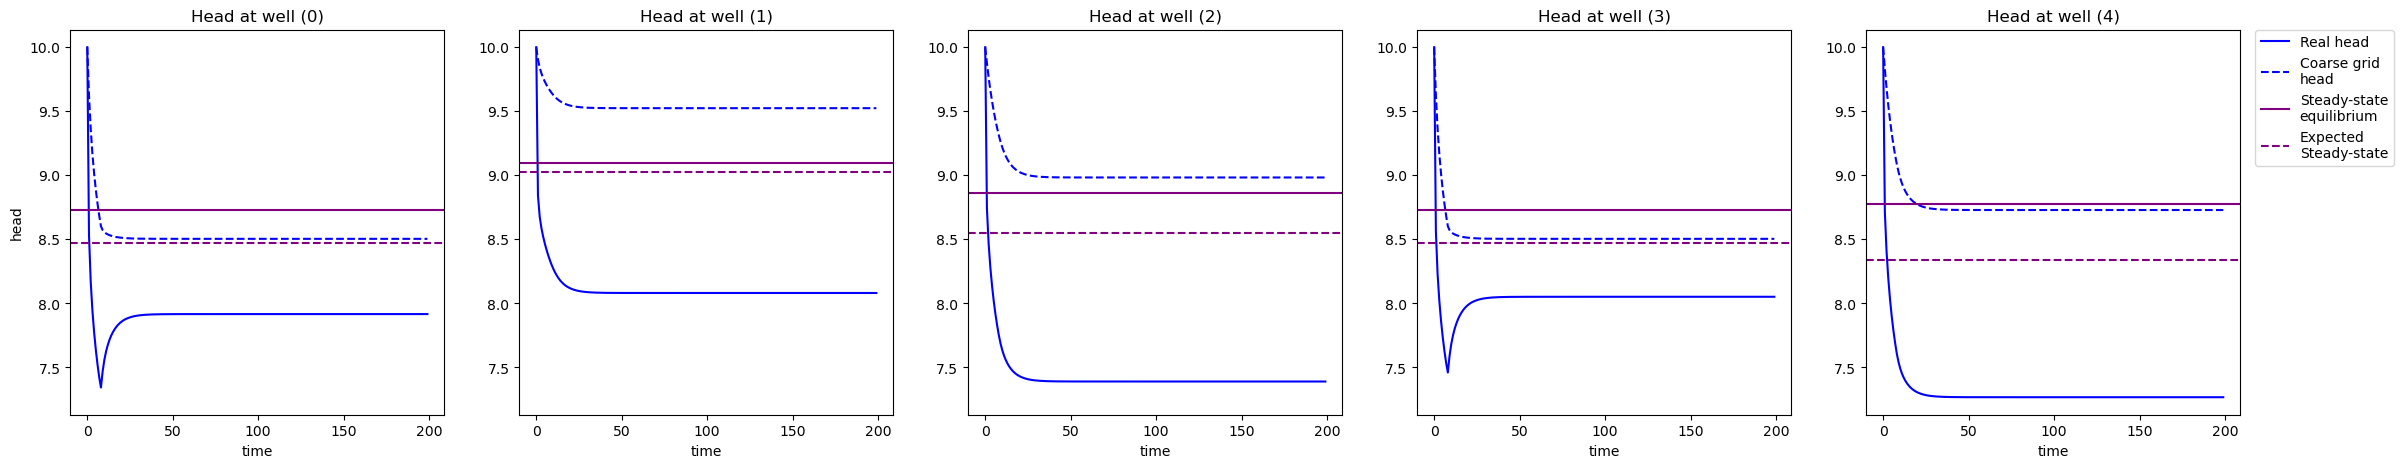

In [349]:
# Display heads evolution
fig_h = plt.figure(figsize=(25+3,5))
ax_h = None
for ii in range(5):
    ax_h = fig_h.add_subplot(1, 5, ii+1, sharey=ax_h)
    ttl = f"Head at well ({ii})"
    ax_h.set_title(ttl)
    ax_h.set_xlabel("time")
    if ii == 0:
        ax_h.set_ylabel("head")
    ax_h.plot(data['h_wells'][ii, :], "b-", label="Real head")
    ax_h.plot(data['avg_h_wells'][ii, :], "b--", label="Coarse grid\nhead")
    ax_h.axhline(xs_reordered[ii], c="purple", label="Steady-state\nequilibrium")
    ax_h.axhline(x_expected_eq[np.nonzero(model.well_to_cell.T)[1]].flatten()[ii], c="purple", linestyle='dashed', label="Expected\nSteady-state")
ax_h.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

In [350]:
u_s_decomposed  = np.array([[u_s[0,0]/2, u_s[3,0], u_s[1,0], u_s[0,0]/2,  u_s[2,0]]]).flatten()

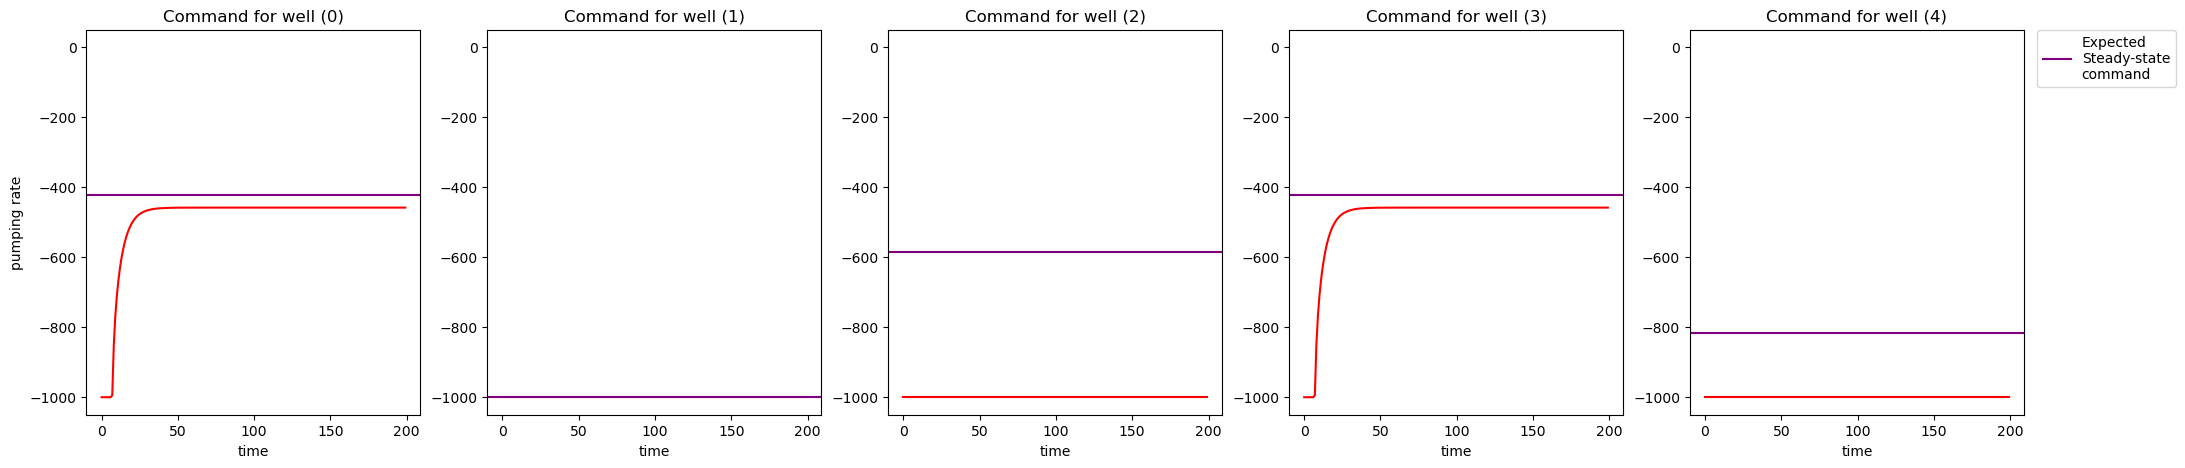

In [351]:
fig_q = plt.figure(figsize=(25,5))
ax_q = None
for ii in range(5):
    ax_q = fig_q.add_subplot(1, 5, ii+1, sharey=ax_q)
    ttl = f"Command for well ({ii})"
    ax_q.set_title(ttl)
    ax_q.set_xlabel("time")
    if ii == 0:
        ax_q.set_ylabel("pumping rate")
    ax_q.plot(data['q_rates'][ii, :], "r-")
    ax_q.axhline(u_s_decomposed[ii], c="purple", label="Expected\nSteady-state\ncommand")
    ax_q.set_ylim([-1050, 50])
ax_q.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

In [352]:
data_ext = np.load("run_data/run_20250512-155535/result_data.npz")

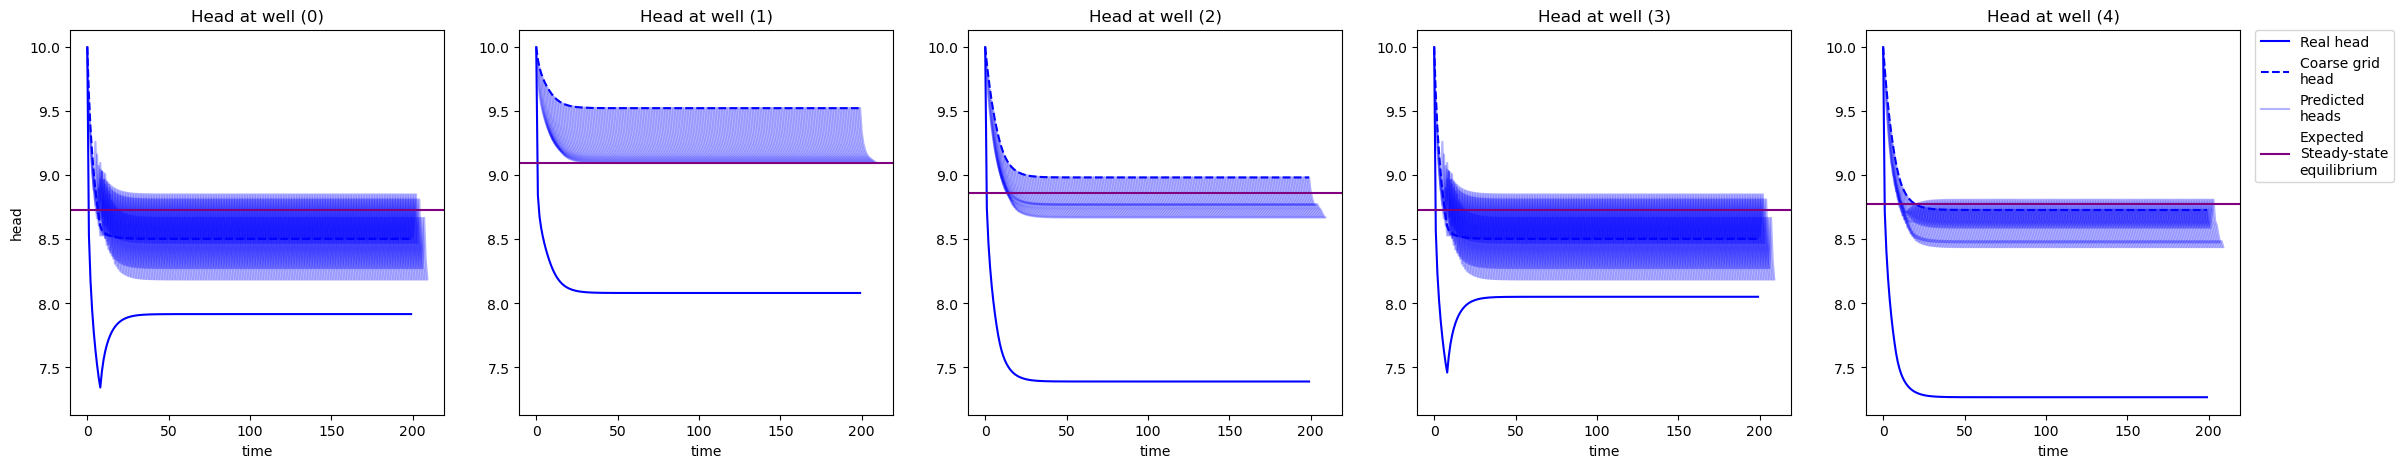

In [353]:
# Display heads evolution
fig_h = plt.figure(figsize=(25+3,5))
ax_h = None
for ii in range(5):
    ax_h = fig_h.add_subplot(1, 5, ii+1, sharey=ax_h)
    ttl = f"Head at well ({ii})"
    ax_h.set_title(ttl)
    ax_h.set_xlabel("time")
    if ii == 0:
        ax_h.set_ylabel("head")
    ax_h.plot(data_ext['h_wells'][ii, :], "b-", label="Real head")
    ax_h.plot(data_ext['avg_h_wells'][ii, :], "b--", label="Coarse grid\nhead")
    # Display predicted evolution
    dt = np.linspace(0,10, 11)
    for t0, h_pred in enumerate(np.rollaxis(data_ext['pred_avg_h_wells'], 2)):
        t = t0 + dt
        ax_h.plot(t, h_pred[ii, :], "b-", alpha=0.3,
                    label="Predicted\nheads" if t0==0 else None)
    ax_h.axhline(xs_reordered[ii], c="purple", label="Expected\nSteady-state\nequilibrium")
ax_h.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

# 14.05: Test if it indeed is a nash equilibrium

Following the cost observation on the 2-cells example (see section 13.05), I want to verify that the steady-state equilibrium is indeed a Nash equilibrium.

In [354]:
parameter_file = "Components/Setup/aquifer_parameters.json"

In [355]:
# Initialize Controller
controller = LTI_LQRc_RHG(
    parameter_file,
    model.A.toarray(), [B.toarray() for B in model.B_v], model.C,
    model.H_x, model.h_x, model.H_u_v, model.h_u_v,
    Q_v = None, R_v = None, M_v = [G.toarray() for G in model.Gamma_v], L_v = [Xi for Xi in model.Xi_v],
    solver='fbrs'
)

In [356]:
u = np.tile(u_s, 10).T
h = controller.h_x_0 @ x_s + controller.h

In [357]:
with gp.Env(empty=True) as env:
    env.setParam('OutputFlag', 0)
    env.start()
    m = gp.Model("matrix1", env)
U_v_splitted = np.split(u, np.cumsum(controller.nu_v)[:-1], axis=1)
H_v = np.split(controller.H.toarray(), np.cumsum(controller.nu_v)[:-1]*controller.K, axis=1)
for v, nu_v in enumerate(controller.nu_v):
    # Define variable and parameters
    u_v = m.addMVar(shape=controller.K*nu_v, lb=-np.inf,
                            vtype=gp.GRB.CONTINUOUS, name="u_v")
    u_minus_v = np.concatenate([U_block.reshape(-1, 1)
                                for p, U_block in enumerate(U_v_splitted)
                                if p != v])
    # Set individual cost
    cost = u_v.T @ controller.R_vv[v] @ u_v + u_v.T @ controller.R_v_minus_v[v] @ u_minus_v + x_s.T @ controller.M_x_v[v] @ u_v + controller.L_v_tilde[v] @ u_v
    m.setObjective(cost, gp.GRB.MINIMIZE)
    # Set constraints
    h_v = h - np.hstack([H_v[p] for p in range(controller.Nv) if p!=v]) @ u_minus_v
    cstrt = (H_v[v] @ u_v)[:,np.newaxis] <= h_v
    m.addConstr(cstrt, name="H")
    # Compare results
    m.optimize()
    u_v_r = U_v_splitted[v].reshape(-1, 1)
    real_cost = u_v_r.T @ controller.R_vv[v] @ u_v_r + u_v_r.T @ controller.R_v_minus_v[v] @ u_minus_v + x_s.T @ controller.M_x_v[v] @ u_v_r + controller.L_v_tilde[v] @ u_v_r
    print(real_cost)
    print(m.ObjVal)
    print(u_v.X)

[[-6195.26664187]]
-8789.247783817671
[-2000.     0. -2000.     0. -2000.     0. -2000.     0. -2000. -2000.]
[[-11575.56090696]]
-13228.694925664568
[-1000. -1000.     0. -1000. -1000. -1000. -1000. -1000.     0. -1000. -1000. -1000. -1000. -1000. -1000. -1000. -1000. -1000. -1000. -1000.]
[[-11001.11984683]]
-11001.119846831763
[-1000. -1000. -1000. -1000. -1000. -1000. -1000. -1000. -1000. -1000.]


Similarly as in the 2-cell case, with this cost definition, the result of fbrs is not the nash equilibrium.

### New cost function

Let's try with the new cost definition:

$l_k(h_{k,t+1},q_{k,t}) = \rho_{c,k} (h_{0,k} - h_{k,t+1}) q_{k,t} - \rho_{p,k} q_{k,t}$

Or:

$J(x_t, u_t) = h_t^T\Gamma q_{t-1} + \Xi q_t = x_t \begin{bmatrix} 0 & \Gamma \\ 0 & 0 \end{bmatrix} x_t + \Xi u_t$, with $x_t^v = \begin{bmatrix} h_t \\ q_{t-1}^v \end{bmatrix}$

In [358]:
nx = model.n_col * model.n_row
# Form new dynamics matrices
A_v_tilde = [sp.block_array([[model.A, sp.csr_array((nx, model.nu_v[v]))], [sp.csr_array((model.nu_v[v], nx)), sp.csr_array((model.nu_v[v], model.nu_v[v]))]]) for v in range(model.n_agent)]
B_tilde = [sp.block_array([[model.B_v[v]], [sp.eye((model.nu_v[v]))]]) for v in range(model.n_agent)]
C_tilde = sp.block_array([[model.C], [sp.csr_array((model.nu_v[0], 1))]])

In [359]:
# Form new constraint matrices
H_x_tilde = np.block([[model.H_x.toarray(), np.zeros((nx, model.nu_v[0]))]])

In [360]:
# Form new Cost matrices
Gamma_v_tilde = [sp.csr_array((nx+model.nu_v[v], model.nu_v[v])) for v in range(model.n_agent)]
Q_v = [sp.block_array([[sp.csr_array((nx, nx)), model.Gamma_v[v]], [sp.csr_array((model.nu_v[v], nx)), sp.csr_array((model.nu_v[v], model.nu_v[v]))]]).toarray() for v in range(model.n_agent)]

#### Steady state equilibrium

$h_s = (I-A)^{-1} (Bu_s + C)$ and $x_s^v = \begin{bmatrix} (I-A)^{-1} B \\ 1_{n_v} \end{bmatrix} u_s + \begin{bmatrix} (I-A)^{-1} C \\ 0 \end{bmatrix} := F^v u_s + G^v$

$J^v(x_s,u_s^v) = x_s^T \tilde\Gamma^v x_s + \Xi^v u_s^v = u_s^T \left({F^v}^T \tilde \Gamma^v F^v\right) u_s + 2 {G^v}^T \tilde \Gamma^v F^v u_s + \Xi^v u_s^v + {G^v}^T \tilde \Gamma^v G^v
:= u_s^T \tilde \Gamma_{eq}^v u_s^v + \tilde \Xi_{eq} u_s + \Xi^v u_s^v + \tilde \zeta$

So:

$J^v(u_s^v, u_s^{-v}) = {u_s^v}^T \tilde \Gamma^v_{eq,[v,v]} u_s^v + {u_s^{-v}}^T \tilde \Gamma^v_{eq,[-v,v]} u_s^v + {u_s^{v}}^T \tilde \Gamma^v_{eq,[v,-v]} u_s^{-v} + \tilde \Xi_{eq,[v]} u_s^{v} + \tilde \Xi_{eq,[-v]} u_s^{-v} + \Xi^v u_s^v + \tilde \zeta$

So:

$\nabla_{u_s^v} J^v(\tilde u_s^v, \tilde u_s^{-v}) = (\tilde \Gamma^v_{eq,[v,v]} + {\tilde \Gamma^v_{eq,[v,v]}}^T) u_s^v + ({\tilde \Gamma^v_{eq,[-v,v]}}^T + \tilde \Gamma^v_{eq,[v,-v]}) u_s^{-v} + {\tilde \Xi_{eq,[v]}}^T + {\Xi^v}^T$

and
$\begin{bmatrix}H_u \\ H_x (I-A)^{-1} B \end{bmatrix} col(u_s^v) \le \begin{bmatrix} h_u \\ h_x - H_x (I-A)^{-1} C \end{bmatrix}$

In [361]:
nu = sum(model.nu_v)
nu_cum = np.cumsum([0]+model.nu_v)
# Construct new Gamma and Xi matrices
I_A_inv = np.linalg.inv(np.eye(nx)-model.A)
B = np.hstack([B.toarray() for B in model.B_v])
One_nv = [np.roll(np.hstack([np.eye(model.nu_v[v]), np.zeros((model.nu_v[v],nu-model.nu_v[v]))]), nu_cum[v]) for v in range(model.n_agent)]
F_v = [np.vstack([I_A_inv @ B, One_nv[v]]) for v in range(model.n_agent)]
G_v = [np.vstack([I_A_inv @ model.C, np.zeros((model.nu_v[v], 1))]) for v in range(model.n_agent)]
Gamma_v_eq = [F_v[v].T @ Q_v[v] @ F_v[v] for v in range(model.n_agent)]
Xi_v_eq = [2* G_v[v].T @ Q_v[v] @ F_v[v] for v in range(model.n_agent)]

In [362]:
# Construct cost matrices
F = np.vstack([Gamma_v_eq[v][nu_cum[v]:nu_cum[v+1], :] for v in range(model.n_agent)])
F += np.vstack([Gamma_v_eq[v][:, nu_cum[v]:nu_cum[v+1]].T for v in range(model.n_agent)])
f = np.vstack([Xi_v_eq[v][:,sum(model.nu_v[:v]): sum(model.nu_v[:v+1])].T + model.Xi_v[v].T for v in range(model.n_agent)])

In [363]:
# Construct constraint matrices
H = np.vstack([
    sp.block_diag(model.H_u_v).toarray(),
    model.H_x @ I_A_inv @ B
])
h = np.vstack([
    sp.vstack(model.h_u_v).toarray(),
    model.h_x.toarray() - I_A_inv @ model.C
])

In [364]:
# Find equilibrium
u_s_0 = np.zeros((nu, 1))
dual_0 = np.zeros((H.shape[0], 1))
u_s, dual, E, out = fbrs(F, f, H, h, u_s_0, dual_0)
x_s = I_A_inv @ (B @ u_s + model.C)

In [365]:
u_s.T, x_s.T

(array([[-2000., -1000., -1000., -1000.]]),
 array([[9.80146487, 9.58436172, 9.3752571 , 9.32812286, 9.649207  , 9.62149778, 9.1607249 , 8.58854381, 8.28802733, 9.26870515, 9.52380136, 8.84849627, 7.53016591, 7.92752182, 9.13758627, 9.62521139, 9.17929293, 8.67767037, 8.7150921 , 9.3541181 , 9.79775127, 9.56579368, 9.28613054, 8.90105809, 9.56379405]]))

#### Check Nash

Static Nash

In [366]:
R_vv = [Gamma_v_eq[v][nu_cum[v]:nu_cum[v+1], nu_cum[v]:nu_cum[v+1]] for v in range(model.n_agent)]
R_v_minus_v = [np.hstack((Gamma_v_eq[v][nu_cum[v]:nu_cum[v+1], :nu_cum[v]], Gamma_v_eq[v][nu_cum[v]:nu_cum[v+1], nu_cum[v+1]:])) for v in range(model.n_agent)]
R_minus_v_v = [np.vstack((Gamma_v_eq[v][:nu_cum[v], nu_cum[v]:nu_cum[v+1]], Gamma_v_eq[v][nu_cum[v+1]:, nu_cum[v]:nu_cum[v+1]])) for v in range(model.n_agent)]
L_v = [Xi_v_eq[v][:,nu_cum[v]:nu_cum[v+1]] + model.Xi_v[v] for v in range(model.n_agent)]
L_minus_v = [np.hstack((Xi_v_eq[v][:,:nu_cum[v]], Xi_v_eq[v][:,nu_cum[v+1]:])) for v in range(model.n_agent)]
zeta_v = [G_v[v].T @ Q_v[v] @ G_v[v] for v in range(model.n_agent)]

In [367]:
with gp.Env(empty=True) as env:
    env.setParam('OutputFlag', 0)
    env.start()
    m = gp.Model("matrix1", env)
U_v_splitted = np.split(u_s, np.cumsum(model.nu_v)[:-1])
H_v = np.split(H, np.cumsum(model.nu_v)[:-1], axis=1)
for v, nu_v in enumerate(model.nu_v):
    # Define variable and parameters
    u_v = m.addMVar(shape=nu_v, lb=-np.inf,
                            vtype=gp.GRB.CONTINUOUS, name="u_v")
    u_minus_v = np.concatenate([U_block.reshape(-1, 1)
                                for p, U_block in enumerate(U_v_splitted)
                                if p != v])
    # Set individual cost
    cost = u_v.T @ R_vv[v] @ u_v + u_minus_v.T @ R_minus_v_v[v] @ u_v + u_v.T @ R_v_minus_v[v] @ u_minus_v + L_v[v] @ u_v + L_minus_v[v] @ u_minus_v + zeta_v[v]
    m.setObjective(cost, gp.GRB.MINIMIZE)
    # Set constraints
    h_v = h - np.hstack([H_v[p] for p in range(model.n_agent) if p!=v]) @ u_minus_v
    cstrt = (H_v[v] @ u_v)[:,np.newaxis] <= h_v
    m.addConstr(cstrt, name="H")
    # Compare results
    m.optimize()
    u_v_r = U_v_splitted[v].reshape(-1, 1)
    real_cost = u_v_r.T @ R_vv[v] @ u_v_r + u_minus_v.T @ R_minus_v_v[v] @ u_v_r + u_v_r.T @ R_v_minus_v[v] @ u_minus_v + L_v[v] @ u_v_r + L_minus_v[v] @ u_minus_v + zeta_v[v]
    print(real_cost)
    print(m.ObjVal)
    print(u_v.X)

[[-19060.33182504]]
-19060.33182503768
[-2000.]
[[-20215.54915673]]
-20215.54915672545
[-1000. -1000.]
[[-10901.05809223]]
-10901.058092234556
[-1000.]


Ok: Indeed Nash equilibrium!

#### Print results

In [368]:
data_ext = np.load("run_data/run_20250516-183948/result_data.npz")

In [369]:
xs_reordered = x_s[np.nonzero(model.well_to_cell.T)[1]].flatten()

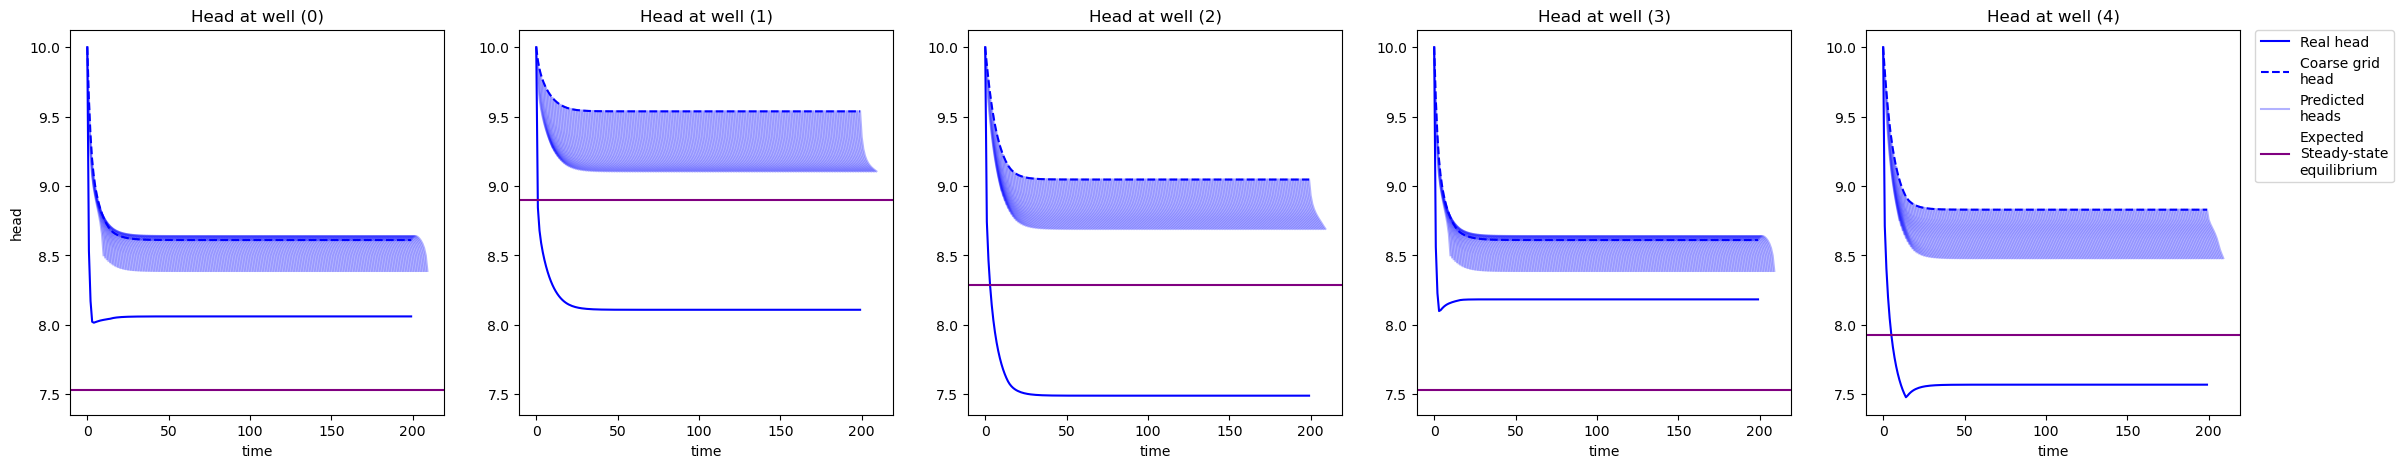

In [370]:
# Display heads evolution
fig_h = plt.figure(figsize=(25+3,5))
ax_h = None
for ii in range(5):
    ax_h = fig_h.add_subplot(1, 5, ii+1, sharey=ax_h)
    ttl = f"Head at well ({ii})"
    ax_h.set_title(ttl)
    ax_h.set_xlabel("time")
    if ii == 0:
        ax_h.set_ylabel("head")
    ax_h.plot(data_ext['h_wells'][ii, :], "b-", label="Real head")
    ax_h.plot(data_ext['avg_h_wells'][ii, :], "b--", label="Coarse grid\nhead")
    # Display predicted evolution
    dt = np.linspace(0,10, 11)
    for t0, h_pred in enumerate(np.rollaxis(data_ext['pred_avg_h_wells'], 2)):
        t = t0 + dt
        ax_h.plot(t, h_pred[ii, :], "b-", alpha=0.3,
                    label="Predicted\nheads" if t0==0 else None)
    ax_h.axhline(xs_reordered[ii], c="purple", label="Expected\nSteady-state\nequilibrium")
ax_h.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

# 19.05: Why are we not pumping $u_s$?

In [371]:
u_s_decomposed  = np.array([[u_s[0,0]/2, u_s[3,0], u_s[1,0], u_s[0,0]/2,  u_s[2,0]]]).flatten()

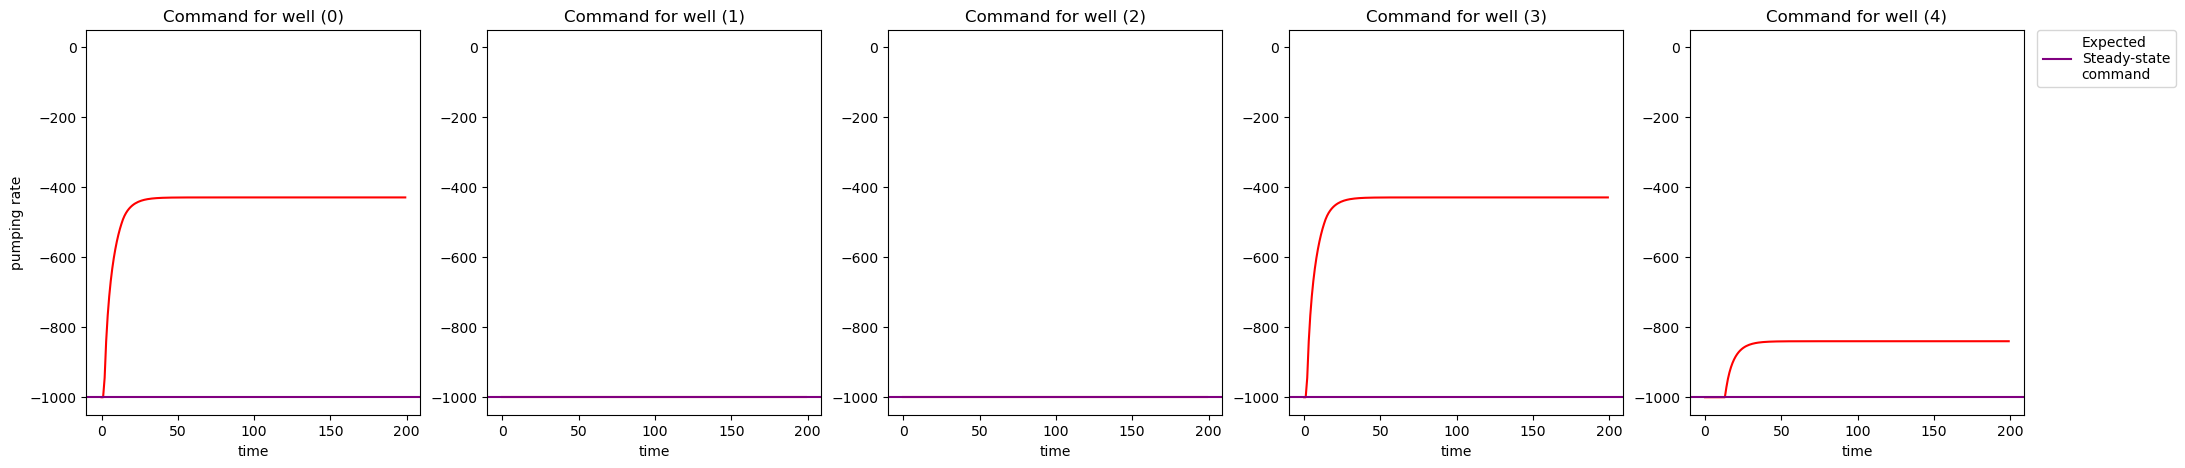

In [372]:
fig_q = plt.figure(figsize=(25,5))
ax_q = None
for ii in range(5):
    ax_q = fig_q.add_subplot(1, 5, ii+1, sharey=ax_q)
    ttl = f"Command for well ({ii})"
    ax_q.set_title(ttl)
    ax_q.set_xlabel("time")
    if ii == 0:
        ax_q.set_ylabel("pumping rate")
    ax_q.plot(data_ext['q_rates'][ii, :], "r-")
    ax_q.axhline(u_s_decomposed[ii], c="purple", label="Expected\nSteady-state\ncommand")
    ax_q.set_ylim([-1050, 50])
ax_q.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

In [373]:
model_ext = SquareCoarseExtendedModel(parameter_file, boundary_condition="Constant Head")

controller_ext = LTI_LQRc_RHG_mixed_state(
        parameter_file,
        model_ext.A.toarray(), [B.toarray() for B in model_ext.B_v], model_ext.C,
        [A.toarray() for A in model_ext.A_s_v], [B.toarray() for B in model_ext.B_s_v], [C.toarray() for C in model_ext.C_s_v],
        model_ext.H_x, model_ext.h_x, model_ext.H_u_v, model_ext.h_u_v,
        None, None,
        Q_v = [G.toarray() for G in model_ext.Gamma_v_tilde], R_v = None, M_v = None, L_v = [Xi for Xi in model_ext.Xi_v],
        solver='fbrs'
    )

/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/site-packages/scipy/sparse/_index.py:210: SparseEfficiencyWarning: Changing the sparsity structure of a csr_array is expensive. lil and dok are more efficient.
  self._set_arrayXarray(i, j, x)
/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/site-packages/scipy/sparse/_index.py:201: SparseEfficiencyWarning: Changing the sparsity structure of a csr_array is expensive. lil and dok are more efficient.
  self._set_arrayXarray_sparse(i, j, x)


In [374]:
x_s_extended = np.vstack((x_s, np.zeros((controller_ext.nu,1))))
u_opt, x_opt = controller_ext.step(x_s_extended)
u_opt[0,:], x_opt[0,:]

(array([-5.30470452e-15, -2.34082656e-14, -3.01202205e+02, -1.00000000e+03]),
 array([9.80146487, 9.80146487, 9.80146487, 9.80146487, 9.80146487, 9.80244234, 9.80483584, 9.80847371, 9.81293854, 9.81780226, 9.82271397]))

Different from $u_s$, $x_s$

In [375]:
controller_ext.A @ x_s + np.hstack(controller.B_v) @ u_s + controller.C

array([[9.80146487],
       [9.58436172],
       [9.3752571 ],
       [9.32812286],
       [9.649207  ],
       [9.62149778],
       [9.1607249 ],
       [8.58854381],
       [8.28802733],
       [9.26870515],
       [9.52380136],
       [8.84849627],
       [7.53016591],
       [7.92752182],
       [9.13758627],
       [9.62521139],
       [9.17929293],
       [8.67767037],
       [8.7150921 ],
       [9.3541181 ],
       [9.79775127],
       [9.56579368],
       [9.28613054],
       [8.90105809],
       [9.56379405]])

In [376]:
(x_s - (controller_ext.A @ x_s + np.hstack(controller.B_v) @ u_s + controller.C)).T

array([[ 0.00000000e+00,  0.00000000e+00,  1.77635684e-15,  0.00000000e+00,  0.00000000e+00,  1.77635684e-15,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  1.77635684e-15,  1.77635684e-15,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  1.77635684e-15,  0.00000000e+00, -1.77635684e-15,  0.00000000e+00,  1.77635684e-15,  0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  1.77635684e-15,  0.00000000e+00]])

In [377]:
u_s_repeated = np.tile(u_s, 10).T
controller_ext._check_nash(u_s_repeated, x_s_extended, sp.csr_array(controller_ext.h_x_0 @ x_s_extended + controller_ext.h))

False

The repeated steady state command $u_s$ is not a nash equilibrium.

In [378]:
x_ss = x_s.copy()
for k in range(10):
    x_ss = np.hstack((x_ss, controller_ext.A @ x_ss[:,[-1]] + np.hstack(controller.B_v) @ u_s + controller.C))
model_ext.select_wells(x_ss)

array([[7.53016591, 7.53016591, 7.53016591, 7.53016591, 7.53016591, 7.53016591, 7.53016591, 7.53016591, 7.53016591, 7.53016591, 7.53016591],
       [8.90105809, 8.90105809, 8.90105809, 8.90105809, 8.90105809, 8.90105809, 8.90105809, 8.90105809, 8.90105809, 8.90105809, 8.90105809],
       [8.28802733, 8.28802733, 8.28802733, 8.28802733, 8.28802733, 8.28802733, 8.28802733, 8.28802733, 8.28802733, 8.28802733, 8.28802733],
       [7.53016591, 7.53016591, 7.53016591, 7.53016591, 7.53016591, 7.53016591, 7.53016591, 7.53016591, 7.53016591, 7.53016591, 7.53016591],
       [7.92752182, 7.92752182, 7.92752182, 7.92752182, 7.92752182, 7.92752182, 7.92752182, 7.92752182, 7.92752182, 7.92752182, 7.92752182]])

In [379]:
u_s_repeated_reordered = np.concatenate([U_block.reshape(-1, 1)
                                       for U_block in \
                                       np.split(u_s_repeated,
                                                np.cumsum(controller_ext.nu_v)[:-1], axis=1)])
x_expected = (controller_ext.A_tilde @ x_s + sp.hstack(controller_ext.B_v_tilde) @ u_s_repeated_reordered + controller_ext.C_tilde).reshape(controller_ext.K+1, controller_ext.nx).T
model_ext.select_wells(x_expected)


array([[7.53016591, 7.53016591, 7.53016591, 7.53016591, 7.53016591, 7.53016591, 7.53016591, 7.53016591, 7.53016591, 7.53016591, 7.53016591],
       [8.90105809, 8.90105809, 8.90105809, 8.90105809, 8.90105809, 8.90105809, 8.90105809, 8.90105809, 8.90105809, 8.90105809, 8.90105809],
       [8.28802733, 8.28802733, 8.28802733, 8.28802733, 8.28802733, 8.28802733, 8.28802733, 8.28802733, 8.28802733, 8.28802733, 8.28802733],
       [7.53016591, 7.53016591, 7.53016591, 7.53016591, 7.53016591, 7.53016591, 7.53016591, 7.53016591, 7.53016591, 7.53016591, 7.53016591],
       [7.92752182, 7.92752182, 7.92752182, 7.92752182, 7.92752182, 7.92752182, 7.92752182, 7.92752182, 7.92752182, 7.92752182, 7.92752182]])

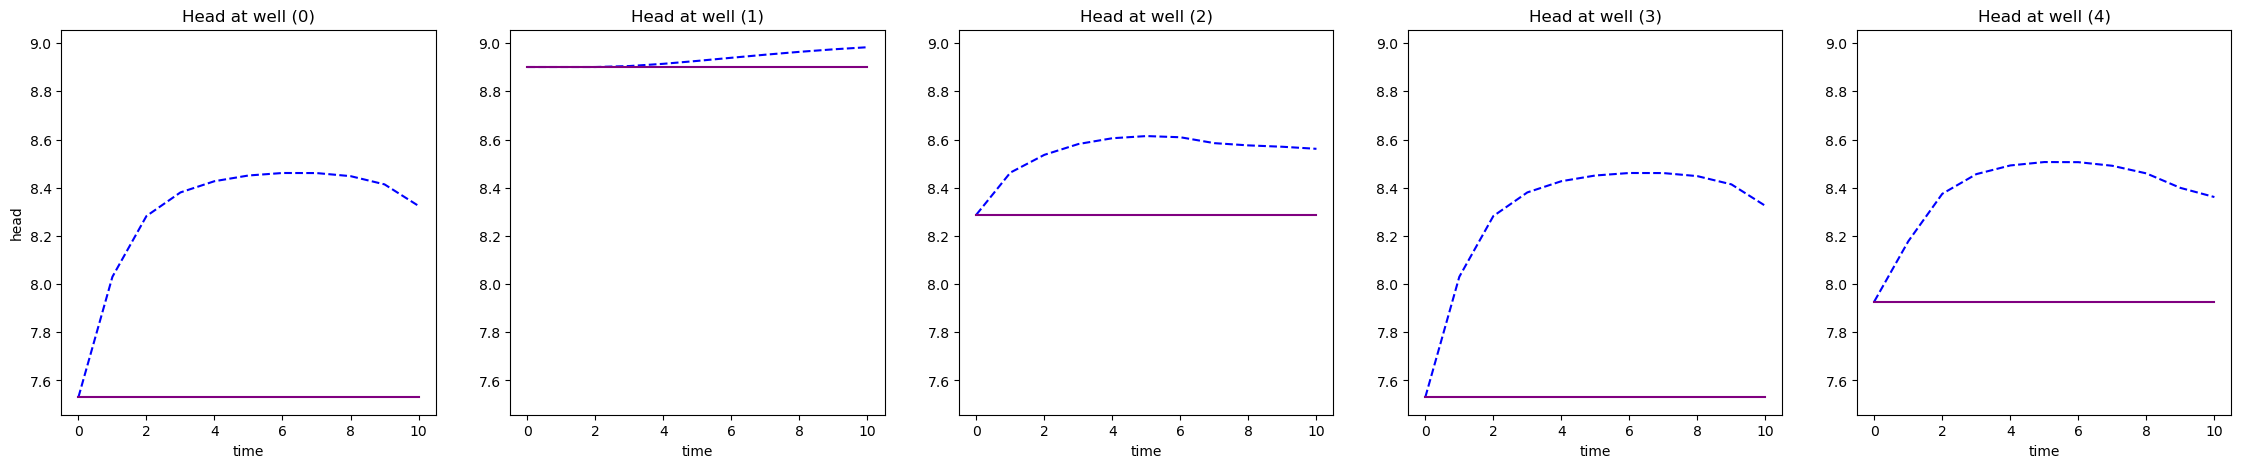

In [380]:
fig_h = plt.figure(figsize=(25+3,5))
ax_h = None
for ii in range(5):
    ax_h = fig_h.add_subplot(1, 5, ii+1, sharey=ax_h)
    ttl = f"Head at well ({ii})"
    ax_h.set_title(ttl)
    ax_h.set_xlabel("time")
    if ii == 0:
        ax_h.set_ylabel("head")
    ax_h.plot(model_ext.select_wells(x_opt)[ii,:], "b--", label="Optimal head")
    ax_h.plot(model_ext.select_wells(x_expected)[ii,:], c="purple", label="Steady state")

In [381]:
u_opt_reordered = np.array([model_ext.translate_input(u) for u in u_opt])

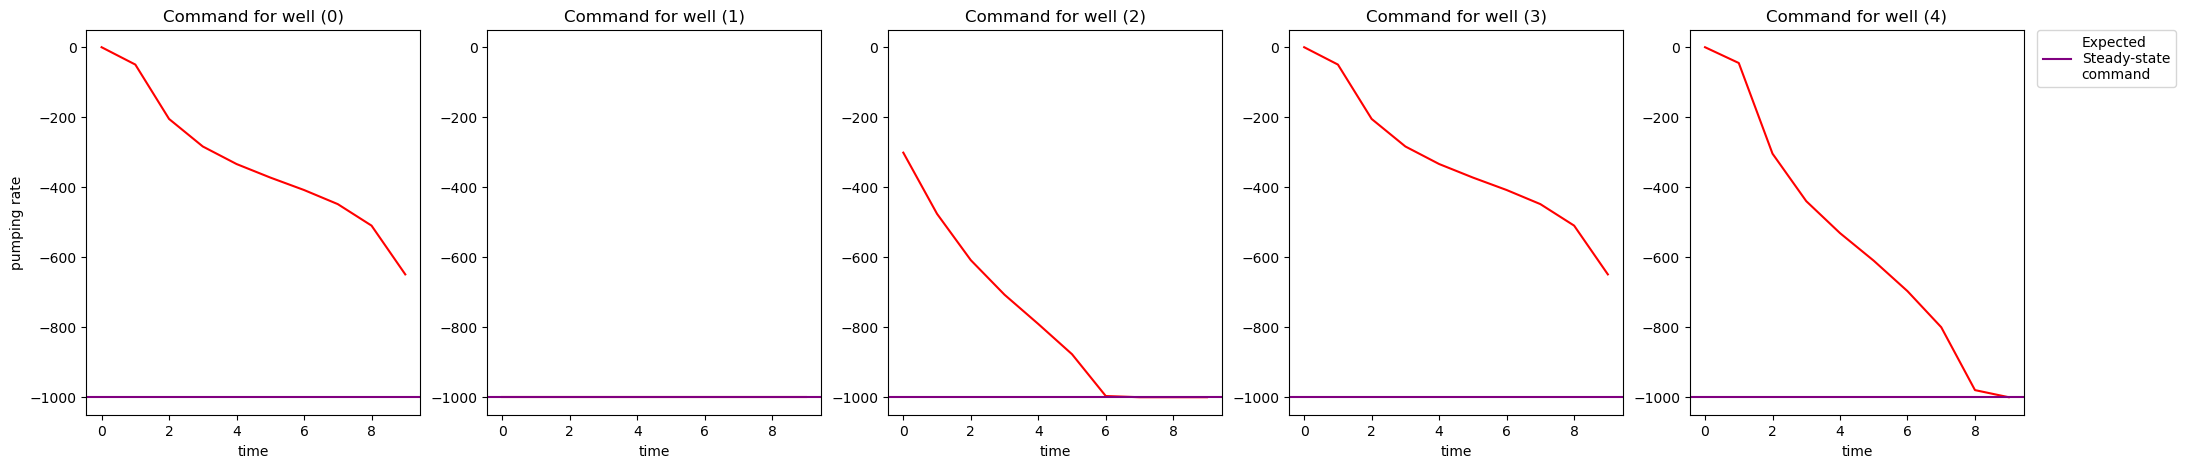

In [382]:
fig_q = plt.figure(figsize=(25,5))
ax_q = None
for ii in range(5):
    ax_q = fig_q.add_subplot(1, 5, ii+1, sharey=ax_q)
    ttl = f"Command for well ({ii})"
    ax_q.set_title(ttl)
    ax_q.set_xlabel("time")
    if ii == 0:
        ax_q.set_ylabel("pumping rate")
    ax_q.plot(u_opt_reordered[:, ii], "r-")
    ax_q.axhline(u_s_decomposed[ii], c="purple", label="Expected\nSteady-state\ncommand")
    ax_q.set_ylim([-1050, 50])
ax_q.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

In [383]:
u_s_translated = np.array([model_ext.translate_input(u) for u in u_s_repeated])

In [384]:
profit = np.zeros((model_ext.n_agent, controller_ext.K))
profit_ss = np.zeros((model_ext.n_agent, controller_ext.K))
for k in range(controller_ext.K):
    for v in range(model_ext.n_agent):
        input_indices = np.nonzero(model_ext.well_to_cell[:,model_ext.well_to_agent==v].T)[1]
        profit[v,k] = -((-model_ext.extraction_cost[v] * (model_ext.initial_state[input_indices] -\
            x_opt[input_indices,k]) * u_opt_reordered[k,model_ext.well_to_agent==v] + \
                model_ext.production_profit[v] * u_opt_reordered[k,model_ext.well_to_agent==v]).sum())
        profit_ss[v,k] = -((-model_ext.extraction_cost[v] * (model_ext.initial_state[input_indices] -\
            x_expected[input_indices,k]) * u_s_translated[k, model_ext.well_to_agent==v] + \
                model_ext.production_profit[v] * u_s_translated[k, model_ext.well_to_agent==v]).sum())

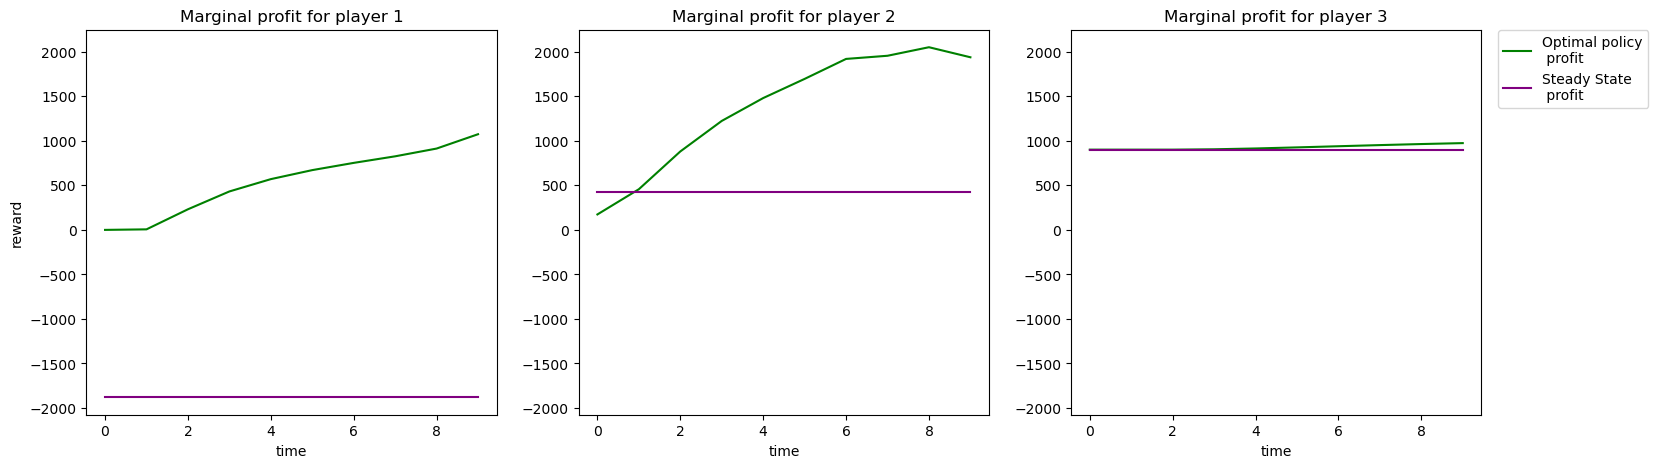

In [385]:
fig_p = plt.figure(figsize=(15+3,5))
ax_p = None
for ii in range(3):
    ax_p = fig_p.add_subplot(1, 3, ii+1, sharey=ax_p)
    ttl = f"Marginal profit for player {ii+1}"
    ax_p.set_title(ttl)
    ax_p.set_xlabel("time")
    if ii == 0:
        ax_p.set_ylabel("reward")
    ax_p.plot(profit[ii, :], "g-", label="Optimal policy\n profit")
    ax_p.plot(profit_ss[ii, :], c="purple", label="Steady State\n profit")
ax_p.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

Steady-state policy allow more profit. So why is it not preferred? -> EDIT: not with the correct computation of cost ignore until END IGNORE flag

In [386]:
h = sp.csr_array(controller_ext.h_x_0 @ x_s_extended + controller_ext.h)

In [387]:
with gp.Env(empty=True) as env:
    env.setParam('OutputFlag', 0)
    env.start()
    m = gp.Model("matrix1", env)
U_v_splitted = np.split(u_s_repeated, np.cumsum(controller_ext.nu_v)[:-1], axis=1)
H_v = np.split(controller_ext.H.toarray(), np.cumsum(controller_ext.nu_v)[:-1]*controller_ext.K, axis=1)
for v, nu_v in enumerate(controller_ext.nu_v):
    # Define variable and parameters
    u_v = m.addMVar(shape=controller_ext.K*nu_v, lb=-np.inf,
                            vtype=gp.GRB.CONTINUOUS, name="u_v")
    u_minus_v = np.concatenate([U_block.reshape(-1, 1)
                                for p, U_block in enumerate(U_v_splitted)
                                if p != v])
    # Set individual cost
    cost = u_v.T @ controller_ext.R_vv[v] @ u_v + u_v.T @ controller_ext.R_v_minus_v[v] @ u_minus_v + x_s_extended.T @ controller_ext.M_x_v[v] @ u_v + controller_ext.L_v_tilde[v] @ u_v
    m.setObjective(cost, gp.GRB.MINIMIZE)
    # Set constraints
    h_v = h - np.hstack([H_v[p] for p in range(controller_ext.Nv) if p!=v]) @ u_minus_v
    cstrt = (H_v[v] @ u_v)[:,np.newaxis] <= h_v
    m.addConstr(cstrt, name="H")
    # Compare results
    m.optimize()
    u_v_r = U_v_splitted[v].reshape(-1, 1)
    real_cost = u_v_r.T @ controller_ext.R_vv[v] @ u_v_r + u_v_r.T @ controller_ext.R_v_minus_v[v] @ u_minus_v + x_s_extended.T @ controller_ext.M_x_v[v] @ u_v_r + controller_ext.L_v_tilde[v] @ u_v_r
    print(real_cost)
    print(m.ObjVal)
    print(u_v.X)

[[9396.68174962]]
-2011.5016135603983
[-1.19575816e-09 -1.09554143e+02 -3.54904729e+02 -4.78429756e+02 -5.60001792e+02 -6.26260428e+02 -6.90715104e+02 -7.67588771e+02 -8.88342742e+02 -1.16194771e+03]
[[-2155.49156726]]
-5195.5266479459915
[-2.83080226e-11 -3.54940308e+02 -5.40768510e+01 -5.40395733e+02 -2.06606539e+02 -6.43439790e+02 -2.87313275e+02 -7.08315120e+02 -3.44601722e+02 -7.61136160e+02 -3.96333647e+02 -8.15705861e+02 -4.54203039e+02 -8.87241457e+02 -5.33109055e+02 -9.99999999e+02 -6.45901577e+02 -1.00000000e+03 -8.82715000e+02 -1.00000000e+03]
[[-9010.58092235]]
-9010.580922345122
[-1000. -1000. -1000. -1000. -1000. -1000. -1000. -1000. -1000. -1000.]


This computation does not output the same "real_cost" for policy $u_s$

In [388]:
v = 0
u_v_r = U_v_splitted[v].reshape(-1, 1)
u_minus_v = np.concatenate([U_block.reshape(-1, 1)
                                for p, U_block in enumerate(U_v_splitted)
                                if p != v])
real_cost = u_v_r.T @ controller_ext.R_vv[v] @ u_v_r + u_v_r.T @ controller_ext.R_v_minus_v[v] @ u_minus_v + x_s_extended.T @ controller_ext.M_x_v[v] @ u_v_r + controller_ext.L_v_tilde[v] @ u_v_r
u_v_r.T, u_minus_v.T, real_cost

(array([[-2000., -2000., -2000., -2000., -2000., -2000., -2000., -2000., -2000., -2000.]]),
 array([[-1000., -1000., -1000., -1000., -1000., -1000., -1000., -1000., -1000., -1000., -1000., -1000., -1000., -1000., -1000., -1000., -1000., -1000., -1000., -1000., -1000., -1000., -1000., -1000., -1000., -1000., -1000., -1000., -1000., -1000.]]),
 array([[9396.68174962]]))

In [389]:
x_expected_cost = 10*((10.-x_s[12])*(2000) - 2*2000)
x_expected_cost

array([9396.68174962])

In [390]:
10.-x_s[12]

array([2.46983409])

Make sense

Plotted cost was wrong (used wrong heads).

END IGNORE

Maybe the previously computed equilibrium is not the good one.

The costs are different as the one outputed in previous computation (14.05)

Let's compute equilibrium again

#### Steady-state equilibrium

$h_s = (I-A)^{-1} (Bu_s + C)$

$J^v(x_s,u_s^v) = x_s^T M^v u_s^v + L^v u_s = u_s^T(B^T{(I-A)^{-1}}^T M^v) u_s^v + (C^T{(I-A)^{-1}}^T M^v + L^v)u_s^v := u_s^T \tilde R^v u_s^v + \tilde L^v u_s^v$
<!-- $J^v(x_s,u_s^v) = \rho_c[(x_0 - x_s)u_s]_{c_v} - \rho_p [u_s]_{c_v}$ -->

So:

$J^v(u_s^v, u_s^{-v}) = {u_s^v}^T \tilde R^v_{[v,v]} u_s^v + {u_s^{-v}}^T \tilde R^v_{[-v,v]} u_s^v + \tilde L_{[v]} u_s^{v}$

So:

$\nabla_{u_s^v} J^v(\tilde u_s^v, \tilde u_s^{-v}) = (\tilde R^v_{[v,v]} + {\tilde R^v_{[v,v]}}^T) u_s^v + {\tilde R^v_{[-v,v]}}^T u_s^{-v} + {\tilde L_{[v]}}^T$

and
$\begin{bmatrix}H_u \\ H_x (I-A)^{-1} B \end{bmatrix} col(u_s^v) \le \begin{bmatrix} h_u \\ h_x - H_x (I-A)^{-1} C \end{bmatrix}$

In [391]:
M_v = [model_ext.input_to_state_v[v] for v in range(model_ext.n_agent)]
L_v = [-10*np.ones((1, model_ext.nx)) @ model_ext.input_to_state_v[v] + 2*np.ones(model_ext.nu_v[v]) for v in range(model_ext.n_agent)]

In [392]:
# Construct new Gamma and Xi matrices
I_A_inv = np.linalg.inv(np.eye(nx)-model_ext.A)
B = np.hstack([B.toarray() for B in model_ext.B_v])
Gamma_v_tilde = [(I_A_inv@B).T @ M for M in M_v]
Xi_v_tilde = [(I_A_inv@model_ext.C).T @ M + L  for M, L in zip(M_v,L_v)]

In [393]:
# Construct cost matrices
F = sp.block_diag([Gamma_v_tilde[v][sum(model_ext.nu_v[:v]): sum(model_ext.nu_v[:v+1])].T \
                   for v in range(model.n_agent)]).toarray()
F += np.vstack([Gamma.T for Gamma in Gamma_v_tilde])
f = np.vstack([Xi.T for Xi in Xi_v_tilde])

In [394]:
# Construct constraint matrices
H = np.vstack([
    sp.block_diag(model_ext.H_u_v).toarray(),
    model_ext.H_x @ I_A_inv @ B
])
h = np.vstack([
    sp.vstack(model_ext.h_u_v).toarray(),
    model_ext.h_x.toarray() - I_A_inv @ model_ext.C
])

In [395]:
# Find equilibrium
u_s_0 = 1000*np.ones((nu, 1))
dual_0 = np.zeros((H.shape[0], 1))
u_s, dual, E, out = fbrs(F, f, H, h, u_s_0, dual_0)
x_s = I_A_inv @ (B @ u_s + model.C)

In [396]:
u_s, x_s.T

(array([[ -845.1870679 ],
        [ -584.66665444],
        [ -817.65051264],
        [-1000.        ]]),
 array([[9.88826301, 9.76250964, 9.62960197, 9.56645286, 9.77320876, 9.79054241, 9.53217357, 9.1894454 , 8.86300069, 9.52638219, 9.74173305, 9.38619682, 8.73300538, 8.77295862, 9.46931931, 9.79019297, 9.53787529, 9.2406502 , 9.17291431, 9.57793643, 9.88116353, 9.73446117, 9.51880584, 9.10011198, 9.6695121 ]]))

#### Nash equilibrium?

In [397]:
u_s_repeated = np.tile(u_s, 10).T
x_s_extended = np.vstack((x_s, np.zeros((controller_ext.nu,1))))

In [398]:
h = sp.csr_array(controller_ext.h_x_0 @ x_s_extended + controller_ext.h)

with gp.Env(empty=True) as env:
    env.setParam('OutputFlag', 0)
    env.start()
    m = gp.Model("matrix1", env)
U_v_splitted = np.split(u_s_repeated, np.cumsum(controller_ext.nu_v)[:-1], axis=1)
H_v = np.split(controller_ext.H.toarray(), np.cumsum(controller_ext.nu_v)[:-1]*controller_ext.K, axis=1)
for v, nu_v in enumerate(controller_ext.nu_v):
    # Define variable and parameters
    u_v = m.addMVar(shape=controller_ext.K*nu_v, lb=-np.inf,
                            vtype=gp.GRB.CONTINUOUS, name="u_v")
    u_minus_v = np.concatenate([U_block.reshape(-1, 1)
                                for p, U_block in enumerate(U_v_splitted)
                                if p != v])
    # Set individual cost
    cost = u_v.T @ controller_ext.R_vv[v] @ u_v + u_v.T @ controller_ext.R_v_minus_v[v] @ u_minus_v + x_s_extended.T @ controller_ext.M_x_v[v] @ u_v + controller_ext.L_v_tilde[v] @ u_v
    m.setObjective(cost, gp.GRB.MINIMIZE)
    # Set constraints
    h_v = h - np.hstack([H_v[p] for p in range(controller_ext.Nv) if p!=v]) @ u_minus_v
    cstrt = (H_v[v] @ u_v)[:,np.newaxis] <= h_v
    m.addConstr(cstrt, name="H")
    # Compare results
    m.optimize()
    u_v_r = U_v_splitted[v].reshape(-1, 1)
    real_cost = u_v_r.T @ controller_ext.R_vv[v] @ u_v_r + u_v_r.T @ controller_ext.R_v_minus_v[v] @ u_minus_v + x_s_extended.T @ controller_ext.M_x_v[v] @ u_v_r + controller_ext.L_v_tilde[v] @ u_v_r
    print(real_cost)
    print(m.ObjVal)
    print(u_v.X)

[[-6195.26664187]]
-6711.087121367924
[-1013.5296647   -996.69639166 -1000.80921991 -1013.50557084 -1032.63841634 -1059.61181157 -1099.45436382 -1165.55930168 -1297.94512253 -1644.67229187]
[[-11575.56090696]]
-12686.580905074954
[ -771.05104546  -988.75527161  -752.62600574  -977.06926412  -761.67297644  -997.50834978  -781.82651067 -1000.          -813.23745668 -1000.          -860.65387318 -1000.          -939.47254348 -1000.         -1000.         -1000.         -1000.         -1000.         -1000.         -1000.        ]
[[-11001.11984683]]
-11001.119846779351
[ -999.99999999  -999.99999999  -999.99999999  -999.99999999  -999.99999999  -999.99999999  -999.99999999  -999.99999999 -1000.         -1000.        ]


Close to the optimal. But staying on steady state seems suboptimal

In [399]:
u_opt, x_opt = controller_ext.step(x_s_extended)
u_opt[0,:], x_opt[0,:]

(array([-1029.00138722,  -779.92485757,  -992.90934005, -1000.        ]),
 array([9.88826301, 9.88826301, 9.88826301, 9.88826301, 9.88826301, 9.88814383, 9.88784981, 9.88737756, 9.88675003, 9.88599593, 9.88513811]))

In [400]:
u_s_repeated_reordered = np.concatenate([U_block.reshape(-1, 1)
                                       for U_block in \
                                       np.split(u_s_repeated,
                                                np.cumsum(controller_ext.nu_v)[:-1], axis=1)])
x_expected = (controller_ext.A_tilde @ x_s + sp.hstack(controller_ext.B_v_tilde) @ u_s_repeated_reordered + controller_ext.C_tilde).reshape(controller_ext.K+1, controller_ext.nx).T

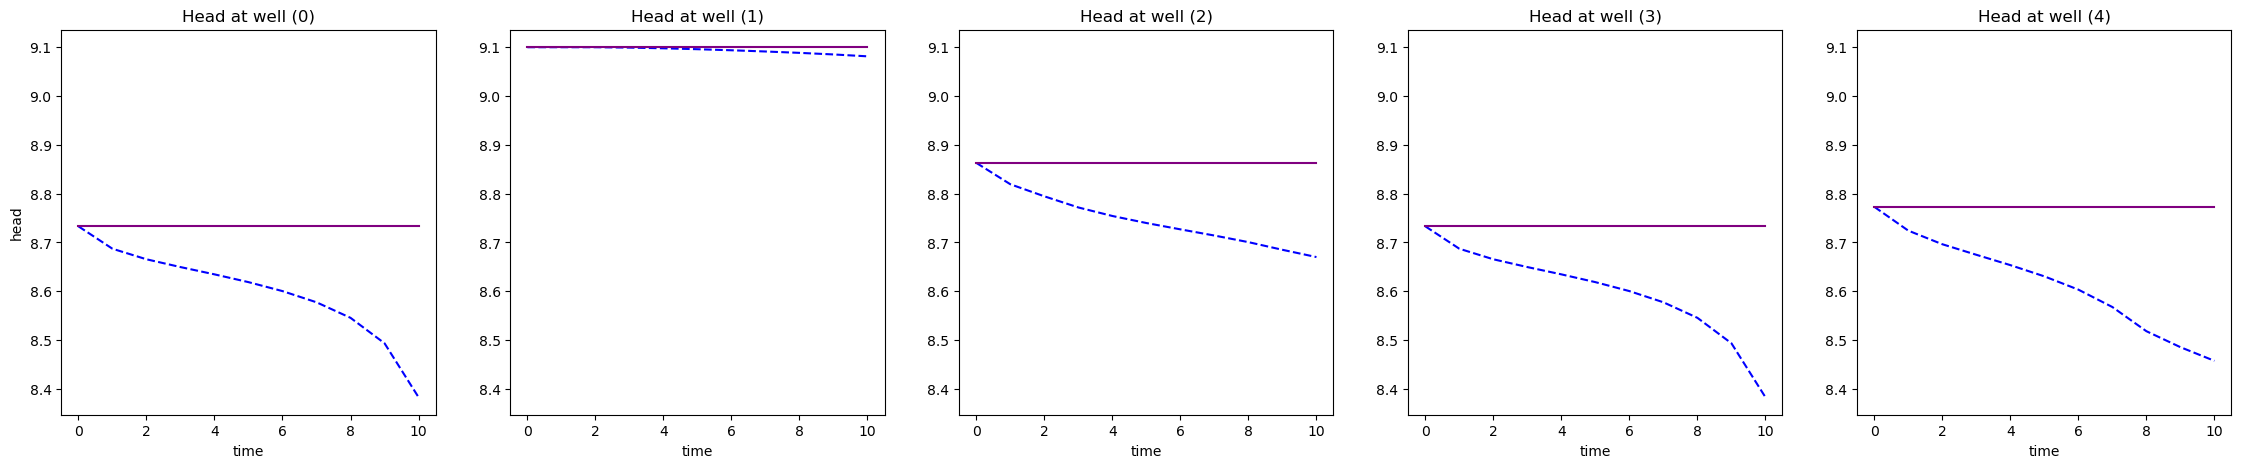

In [401]:
fig_h = plt.figure(figsize=(25+3,5))
ax_h = None
for ii in range(5):
    ax_h = fig_h.add_subplot(1, 5, ii+1, sharey=ax_h)
    ttl = f"Head at well ({ii})"
    ax_h.set_title(ttl)
    ax_h.set_xlabel("time")
    if ii == 0:
        ax_h.set_ylabel("head")
    ax_h.plot(model_ext.select_wells(x_opt)[ii,:], "b--", label="Optimal head")
    ax_h.plot(model_ext.select_wells(x_expected)[ii,:], c="purple", label="Steady state")

In [428]:
u_opt_reordered = np.array([model_ext.translate_input(u) for u in u_opt])
u_s_decomposed  = model_ext.input_to_well.toarray() @ (u_s/np.count_nonzero(model_ext.input_to_well.toarray(), axis=0)[:,np.newaxis])

/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/site-packages/matplotlib/cbook.py:1719: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  return math.isfinite(val)
/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/site-packages/matplotlib/cbook.py:1719: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  return math.isfinite(val)
/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/site-packages/matplotlib/cbook.py:1719: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this

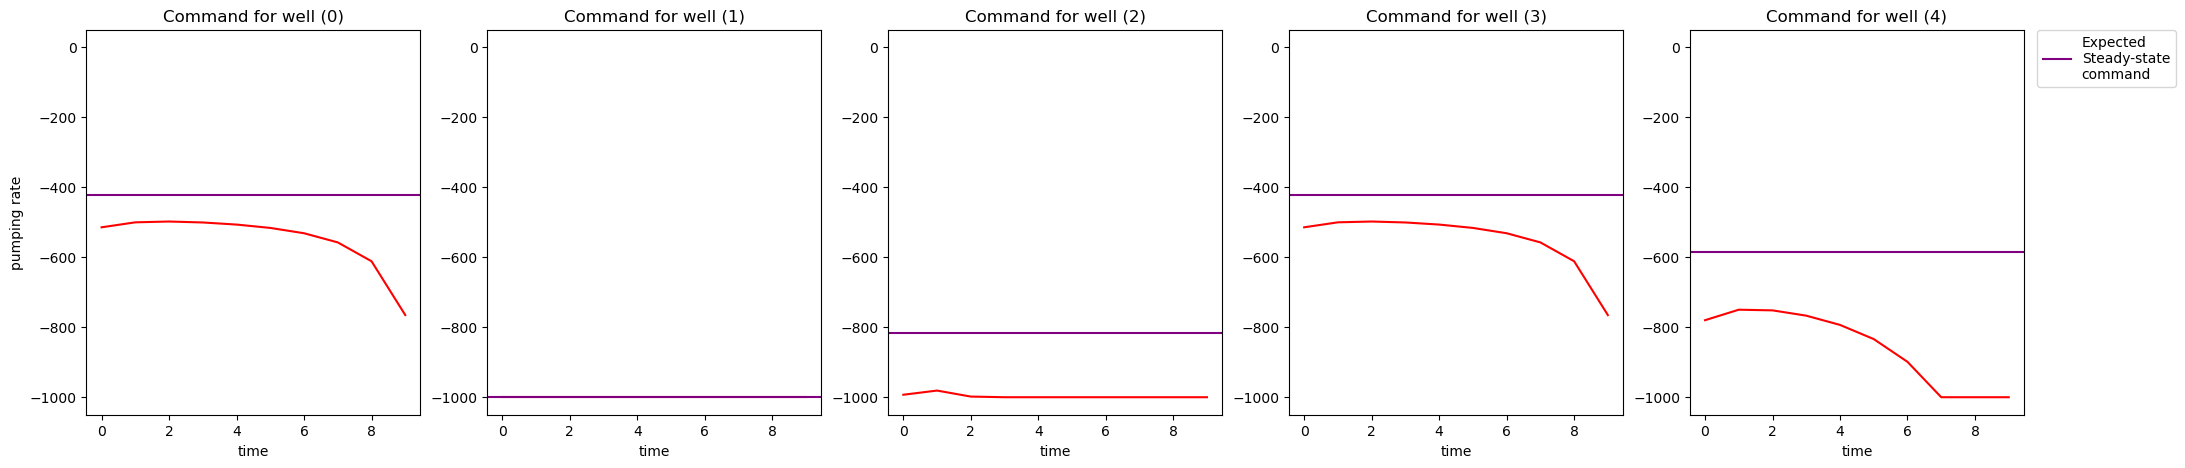

In [430]:
fig_q = plt.figure(figsize=(25,5))
ax_q = None
for ii in range(5):
    ax_q = fig_q.add_subplot(1, 5, ii+1, sharey=ax_q)
    ttl = f"Command for well ({ii})"
    ax_q.set_title(ttl)
    ax_q.set_xlabel("time")
    if ii == 0:
        ax_q.set_ylabel("pumping rate")
    ax_q.plot(u_opt_reordered[:, ii], "r-")
    ax_q.axhline(u_s_decomposed[ii], c="purple", label="Expected\nSteady-state\ncommand")
    ax_q.set_ylim([-1050, 50])
ax_q.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

In [404]:
u_s_translated = np.array([model_ext.translate_input(u) for u in u_s_repeated])

In [432]:
profit = np.zeros((model_ext.n_agent, controller_ext.K))
profit_ss = np.zeros((model_ext.n_agent, controller_ext.K))
for k in range(controller_ext.K):
    for v in range(model_ext.n_agent):
        input_indices = np.nonzero(model_ext.well_to_cell[:,model_ext.well_to_agent==v].T)[1]
        profit[v,k] = -((-model_ext.extraction_cost[v] * (model_ext.initial_state[input_indices] -\
            x_opt[input_indices,k]) * u_opt_reordered[k,model_ext.well_to_agent==v] + \
                model_ext.production_profit[v] * u_opt_reordered[k,model_ext.well_to_agent==v]).sum())
        profit_ss[v,k] = -((-model_ext.extraction_cost[v] * (model_ext.initial_state[input_indices] -\
            x_expected[input_indices,k]) * u_s_translated[k, model_ext.well_to_agent==v] + \
                model_ext.production_profit[v] * u_s_translated[k, model_ext.well_to_agent==v]).sum())

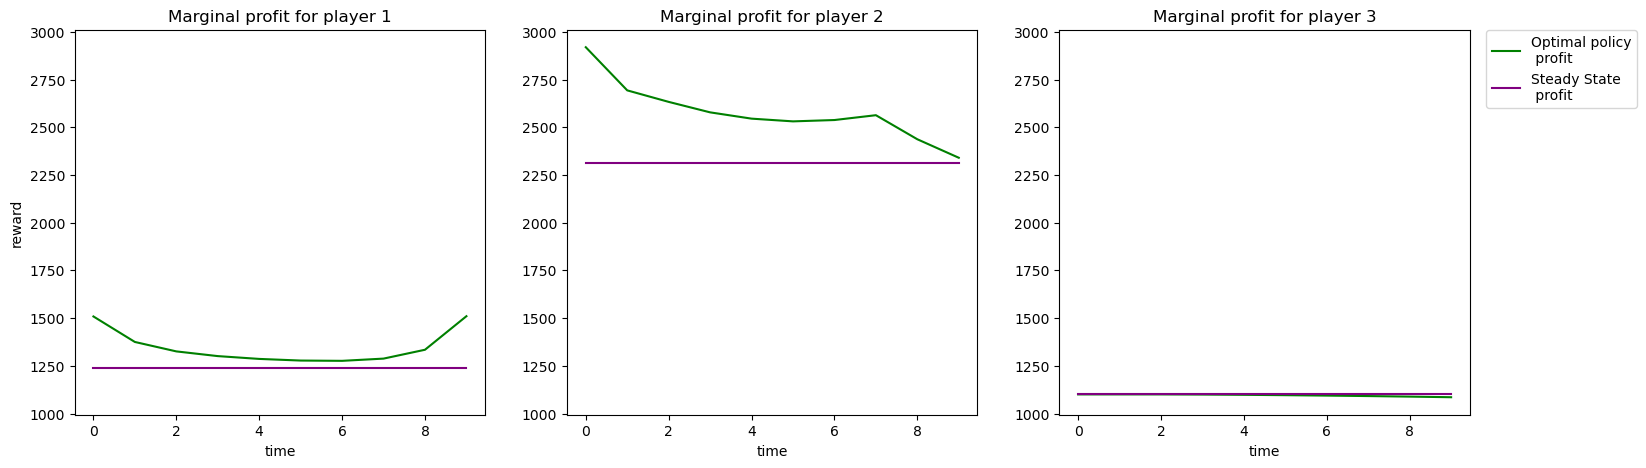

In [433]:
fig_p = plt.figure(figsize=(15+3,5))
ax_p = None
for ii in range(3):
    ax_p = fig_p.add_subplot(1, 3, ii+1, sharey=ax_p)
    ttl = f"Marginal profit for player {ii+1}"
    ax_p.set_title(ttl)
    ax_p.set_xlabel("time")
    if ii == 0:
        ax_p.set_ylabel("reward")
    ax_p.plot(profit[ii, :], "g-", label="Optimal policy\n profit")
    ax_p.plot(profit_ss[ii, :], c="purple", label="Steady State\n profit")
ax_p.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

Ok. The dynamic state is above. Steady is not optimal.

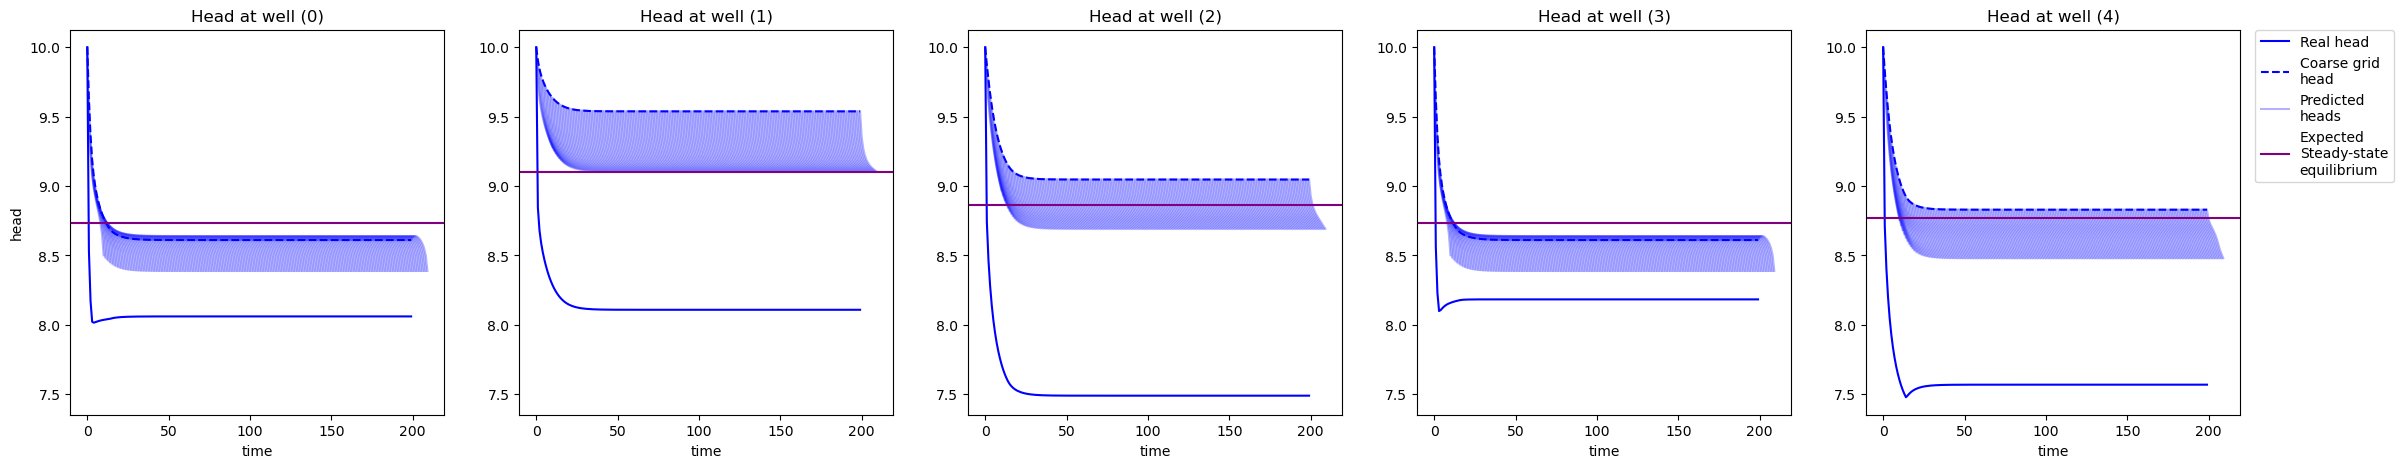

In [434]:
# Display heads evolution
fig_h = plt.figure(figsize=(25+3,5))
ax_h = None
for ii in range(5):
    ax_h = fig_h.add_subplot(1, 5, ii+1, sharey=ax_h)
    ttl = f"Head at well ({ii})"
    ax_h.set_title(ttl)
    ax_h.set_xlabel("time")
    if ii == 0:
        ax_h.set_ylabel("head")
    ax_h.plot(data_ext['h_wells'][ii, :], "b-", label="Real head")
    ax_h.plot(data_ext['avg_h_wells'][ii, :], "b--", label="Coarse grid\nhead")
    # Display predicted evolution
    dt = np.linspace(0,10, 11)
    for t0, h_pred in enumerate(np.rollaxis(data_ext['pred_avg_h_wells'], 2)):
        t = t0 + dt
        ax_h.plot(t, h_pred[ii, :], "b-", alpha=0.3,
                    label="Predicted\nheads" if t0==0 else None)
    ax_h.axhline(model_ext.select_wells(x_expected)[ii,0], c="purple", label="Expected\nSteady-state\nequilibrium")
ax_h.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/site-packages/matplotlib/cbook.py:1719: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  return math.isfinite(val)
/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/site-packages/matplotlib/cbook.py:1719: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  return math.isfinite(val)
/Users/leonardchanfreau/miniconda3/envs/modflowenv/lib/python3.13/site-packages/matplotlib/cbook.py:1719: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this

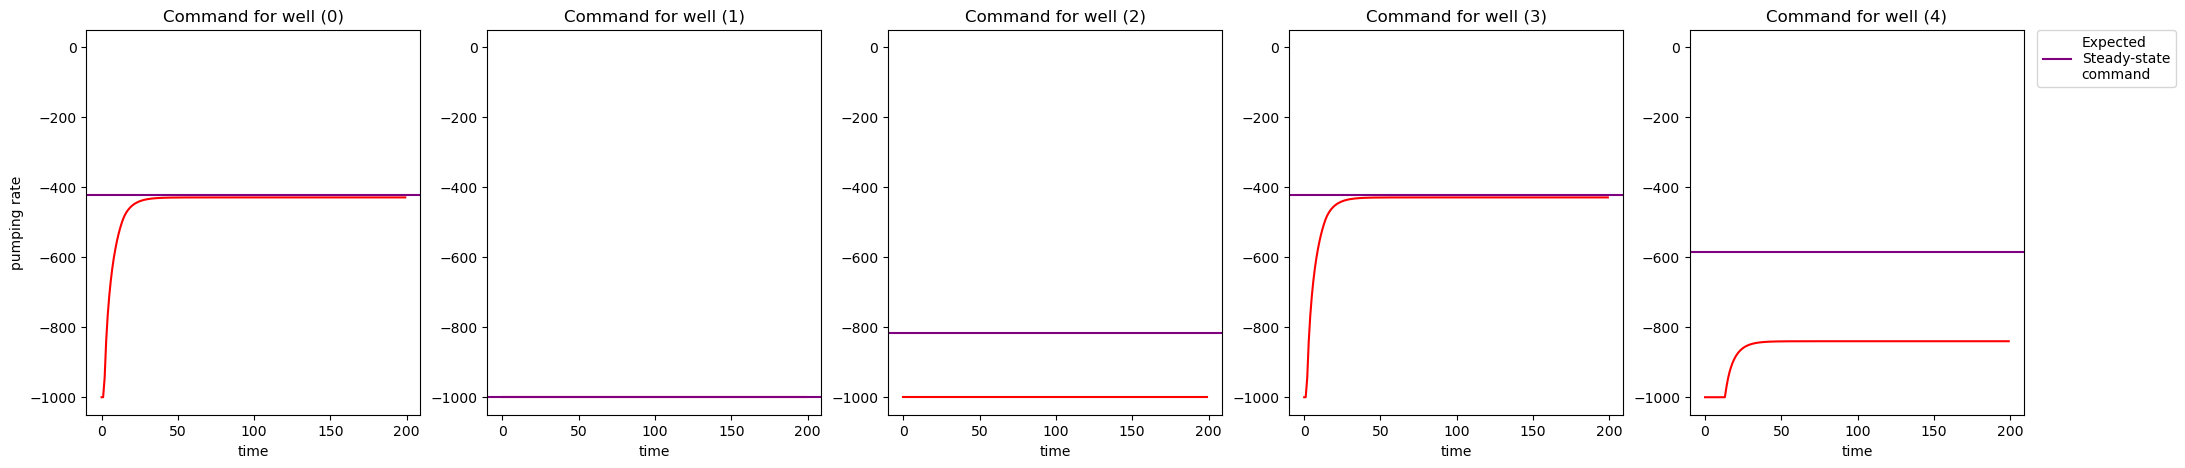

In [436]:
fig_q = plt.figure(figsize=(25,5))
ax_q = None
for ii in range(5):
    ax_q = fig_q.add_subplot(1, 5, ii+1, sharey=ax_q)
    ttl = f"Command for well ({ii})"
    ax_q.set_title(ttl)
    ax_q.set_xlabel("time")
    if ii == 0:
        ax_q.set_ylabel("pumping rate")
    ax_q.plot(data_ext['q_rates'][ii, :], "r-")
    ax_q.axhline(u_s_decomposed[ii], c="purple", label="Expected\nSteady-state\ncommand")
    ax_q.set_ylim([-1050, 50])
ax_q.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)

# 20.05: Longer time-horizon

In [437]:
data_ext_longer = np.load("run_data/run_20250520-103626/result_data.npz")

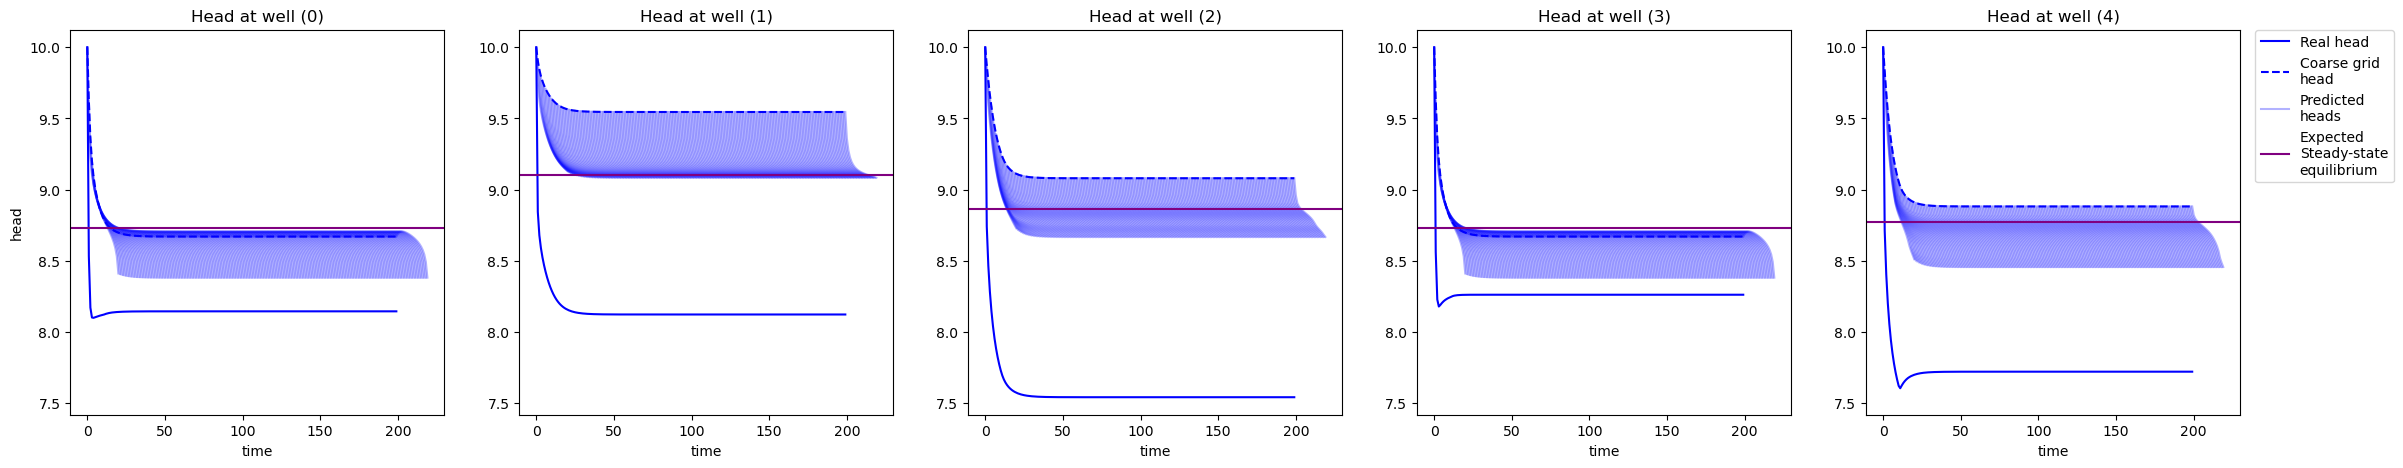

In [438]:
# Display heads evolution
fig_h = plt.figure(figsize=(25+3,5))
ax_h = None
for ii in range(5):
    ax_h = fig_h.add_subplot(1, 5, ii+1, sharey=ax_h)
    ttl = f"Head at well ({ii})"
    ax_h.set_title(ttl)
    ax_h.set_xlabel("time")
    if ii == 0:
        ax_h.set_ylabel("head")
    ax_h.plot(data_ext_longer['h_wells'][ii, :], "b-", label="Real head")
    ax_h.plot(data_ext_longer['avg_h_wells'][ii, :], "b--", label="Coarse grid\nhead")
    # Display predicted evolution
    dt = np.linspace(0,20, 21)
    for t0, h_pred in enumerate(np.rollaxis(data_ext_longer['pred_avg_h_wells'], 2)):
        t = t0 + dt
        ax_h.plot(t, h_pred[ii, :], "b-", alpha=0.3,
                    label="Predicted\nheads" if t0==0 else None)
    ax_h.axhline(model_ext.select_wells(x_expected)[ii,0], c="purple", label="Expected\nSteady-state\nequilibrium")
ax_h.legend(bbox_to_anchor=(1.04, 1), loc="upper left", borderaxespad=0)